In [42]:
import os
import json
import random
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pickle
import pandas as pd
import torch
import torch.nn.functional as F
import re
import time
from scipy.stats import gaussian_kde
from sklearn.neighbors import KDTree


In [43]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'  # Catch errors immediately

import torch
torch.cuda.empty_cache()

In [44]:
from modules_general import (
    SimpleStackedHamiltonianNetwork_general,
    SegmentDataLoader_general,
    train_model_general,
    make_validation_batch,
    load_checkpoint,
    load_segment_progress,
    plot_segment_progress,
    summarise_segment_progress,
    InverseStackedHamiltonianNetwork_general,
    )

In [53]:
from modules import (    
    get_data_from_trajectory_id,
    visualize_epoch_metrics,
    prediction_loss_euclidean,
    plot_summary_statistics,
    prediction_loss,
    )

In [6]:
save_dir_path = "./save_directory_HH_general_1" 


In [7]:


with open("all_dataframes_HH_portable.pkl", "rb") as f:
    portable = pickle.load(f)

loaded_dfs = {}
for name, d in portable.items():
    df = pd.DataFrame(d["data"], columns=d["columns"])
    df.index = pd.Index(d["index_values"], name=d["index_name"])
    loaded_dfs[name] = df

# Verify shapes survived the round trip
print(f"{'name':<20}{'loaded shape':<16}status")
for name, d in portable.items():
    got, exp = loaded_dfs[name].shape, d["shape"]
    status = "OK" if got == exp else f"!! MISMATCH (expected {exp})"
    print(f"{name:<20}{str(got):<16}{status}")

name                loaded shape    status
train_df            (16032, 7)      OK
val_df              (5344, 6)       OK
test_df             (5344, 6)       OK
train_id_df         (48, 11)        OK
val_id_df           (16, 9)         OK
test_id_df          (16, 9)         OK
train_seg_df        (16032, 8)      OK
train_seg_id_df     (288, 14)       OK
val_seg_df          (5344, 7)       OK
val_seg_id_df       (96, 12)        OK


In [8]:
train_df        = loaded_dfs["train_df"]
val_df          = loaded_dfs["val_df"]
test_df         = loaded_dfs["test_df"]

train_id_df     = loaded_dfs["train_id_df"]
val_id_df       = loaded_dfs["val_id_df"]
test_id_df      = loaded_dfs["test_id_df"]

train_seg_df    = loaded_dfs["train_seg_df"]
train_seg_id_df = loaded_dfs["train_seg_id_df"]
val_seg_df      = loaded_dfs["val_seg_df"]
val_seg_id_df   = loaded_dfs["val_seg_id_df"]

In [9]:
test_id_df.columns

Index(['trajectory_id', 'x0', 'y0', 'px0', 'py0', 'energy', 'generated_points',
       'start_index', 'end_index'],
      dtype='object')

In [11]:

SIGMA2_OLD = 0.1
HH_COORDS = ['x', 'y', 'px', 'py']

# ---- paste the two printed lines here (replace the placeholder numbers) ----
OLD_WITHIN_VAR = [
    ('Task1', {'x': 5.705888e-01, 'u': 6.005445e-01}),
    ('Task2', {'x': 6.691010e-01, 'u': 1.702431e+00}),
]

# 1) HH signal variances -----------------------------------------------------
grp = train_seg_df.groupby(['trajectory_id', 'segment_id'])
within = grp[HH_COORDS].var(ddof=0).mean()      # mean within-segment variance
pooled = train_seg_df[HH_COORDS].var(ddof=0)    # variance over all samples

print("=== HH ===")
for c in HH_COORDS:
    print(f"  {c:>2}: within_var={within[c]:.4e}  pooled_var={pooled[c]:.4e}  "
          f"SNR_within@0.1={within[c]/SIGMA2_OLD:6.2f}")

# 2) old validated per-channel SNR band -------------------------------------
old_snr = [v/SIGMA2_OLD for _, d in OLD_WITHIN_VAR for v in d.values()]
SNR_min_old, SNR_max_old = min(old_snr), max(old_snr)
print(f"\nOld validated per-channel SNR band (within): [{SNR_min_old:.2f}, {SNR_max_old:.2f}]")

# 3) worst HH channel -> single-sigma range ---------------------------------
worst_c = min(HH_COORDS, key=lambda c: within[c]); minVar = within[worst_c]
s2_hi = minVar / SNR_min_old     # match old DIRTIEST channel -> largest sigma
s2_lo = minVar / SNR_max_old     # match old CLEANEST channel -> smallest sigma
print(f"\nHH worst channel: '{worst_c}'  within_var={minVar:.4e}")
print(f"SNR-matched sigma^2 in [{s2_lo:.4e}, {s2_hi:.4e}]"
      f"  ->  sigma in [{s2_lo**0.5:.4f}, {s2_hi**0.5:.4f}]")

# 4) chaos diagnostic --------------------------------------------------------
tl = train_seg_df['tau_L'].replace([np.inf, -np.inf], np.nan)
tl = tl[(tl.notna()) & (tl > 0)]
print(f"\ntau_L>0 : count={tl.size}  min={tl.min():.3f}  p1={tl.quantile(.01):.3f}  "
      f"p5={tl.quantile(.05):.3f}  median={tl.median():.3f}")

seg_tauL = grp['tau_L'].apply(lambda s: s[(s > 0) & np.isfinite(s)].min())
seg_span = grp['t'].apply(lambda s: s.max() - s.min())
print(f"\nSegment t-span: min={seg_span.min():.3f}  median={seg_span.median():.3f}  "
      f"max={seg_span.max():.3f}   (CHECK: physical time, same units as tau_L?)")
ratio = (seg_span / seg_tauL).replace([np.inf, -np.inf], np.nan).dropna()
print(f"T_seg/tau_L : median={ratio.median():.2f}  p95={ratio.quantile(.95):.2f}  max={ratio.max():.2f}")

=== HH ===
   x: within_var=5.6416e-02  pooled_var=6.3115e-02  SNR_within@0.1=  0.56
   y: within_var=4.9324e-02  pooled_var=5.4818e-02  SNR_within@0.1=  0.49
  px: within_var=5.0699e-02  pooled_var=5.2567e-02  SNR_within@0.1=  0.51
  py: within_var=4.5160e-02  pooled_var=4.6460e-02  SNR_within@0.1=  0.45

Old validated per-channel SNR band (within): [5.71, 17.02]

HH worst channel: 'py'  within_var=4.5160e-02
SNR-matched sigma^2 in [2.6527e-03, 7.9147e-03]  ->  sigma in [0.0515, 0.0890]

tau_L>0 : count=8604  min=8.563  p1=10.202  p5=12.170  median=20.820

Segment t-span: min=7.057  median=8.408  max=8.559   (CHECK: physical time, same units as tau_L?)
T_seg/tau_L : median=0.50  p95=0.79  max=0.99



📊 Metric summaries:
  Lowest loss of metric 'val_prediction_loss_' recorded in epoch 2111 with the value: 0.0419, the losses of the last 5 epochs are: ['0.0437', '0.0440', '0.0438', '0.0429', '0.0419']
  Lowest loss of metric 'val_prediction_loss_training_set' recorded in epoch 2050 with the value: 0.0329, the losses of the last 5 epochs are: ['0.0351', '0.0341', '0.0344', '0.0338', '0.0331']
  Lowest loss of metric 'train_total_loss_' recorded in epoch 2039 with the value: 0.4716, the losses of the last 5 epochs are: ['0.4756', '0.4749', '0.4746', '0.4759', '0.4728']
  Lowest loss of metric 'train_hsic_loss_' recorded in epoch 625 with the value: 0.0000, the losses of the last 5 epochs are: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000']
  Lowest loss of metric 'validation_criterio' recorded in epoch 2111 with the value: 0.0419, the losses of the last 5 epochs are: ['0.0437', '0.0440', '0.0438', '0.0429', '0.0419']
  Lowest loss of metric 'mean_grad_norm_' recorded in epoch 1 with

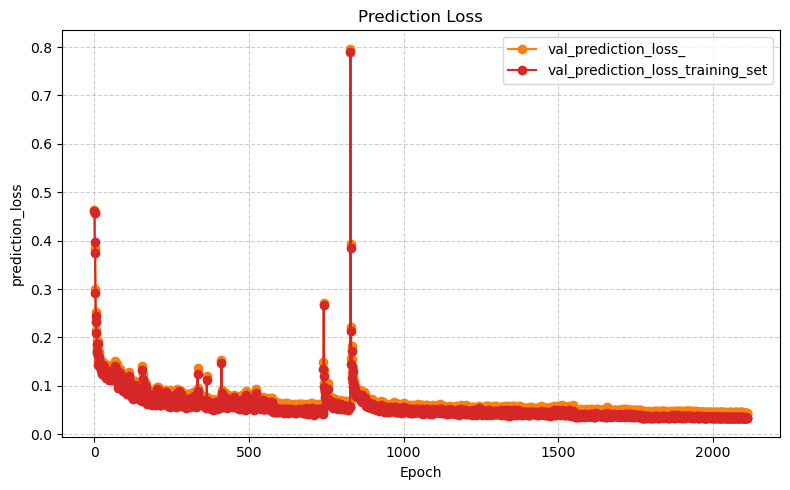

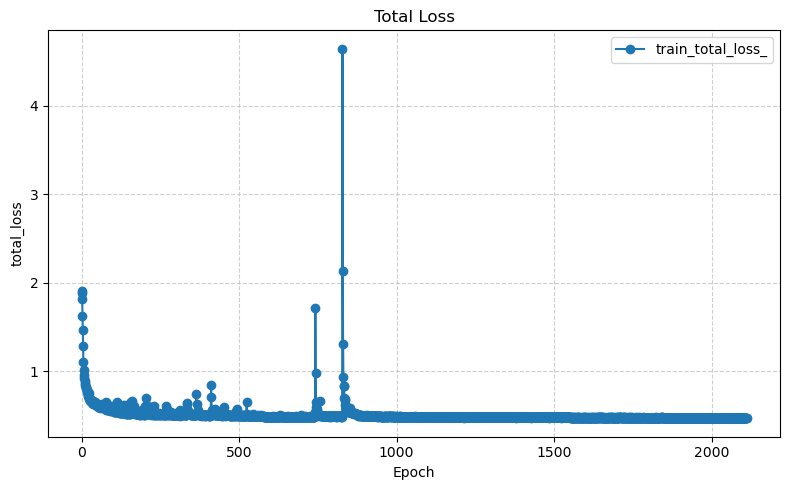

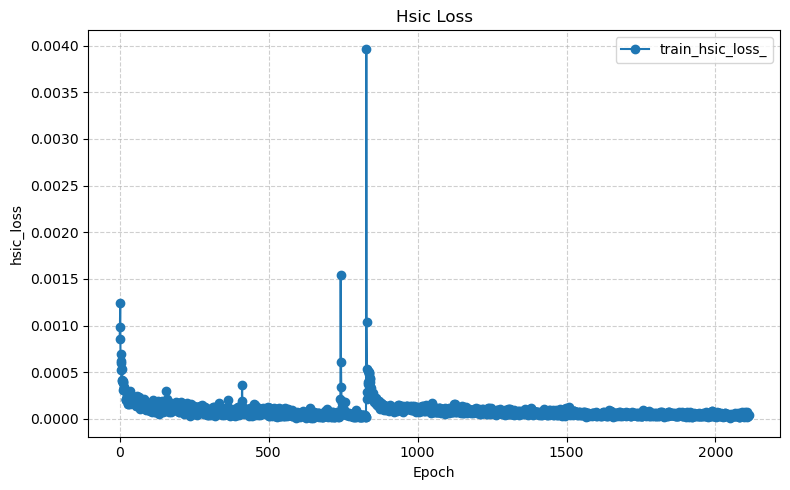

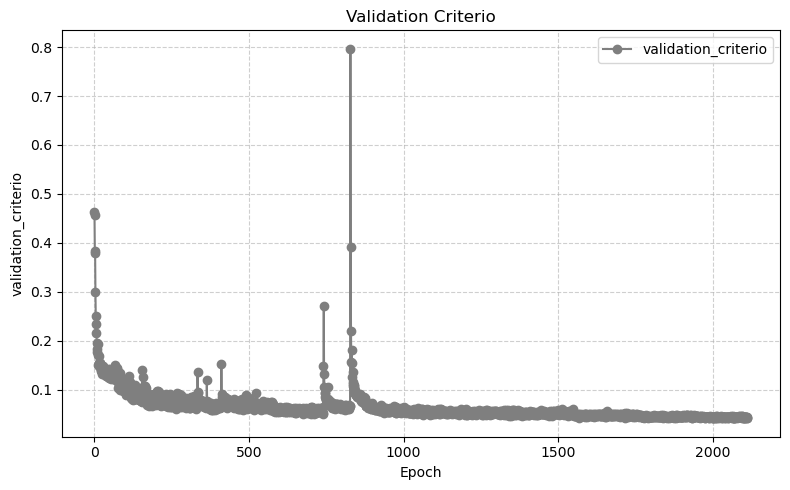

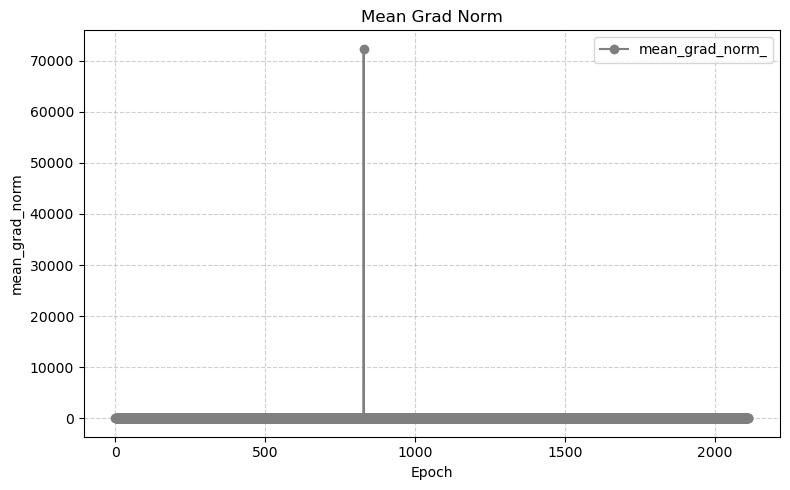

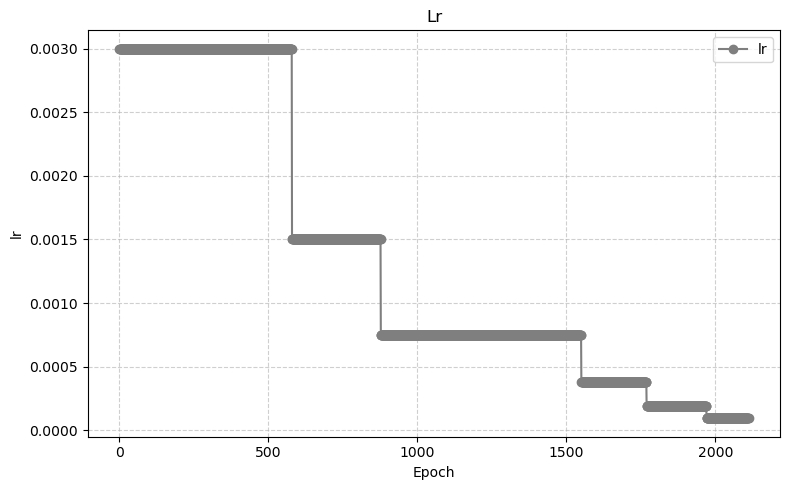

In [58]:
visualize_epoch_metrics(
 save_dir_path,
["val_prediction_loss_", "val_prediction_loss_training_set", "train_total_loss_", "train_hsic_loss_" , "validation_criterio", "mean_grad_norm_", "lr"],
plot_on_same_graph=True,
verbose=True,
specific_epochs=None
)



Final-epoch (2111) val_train_pred_loss by frac_regular tercile:
  frac_regular in [0.000,0.140]: n= 96  mean=0.0332  median=0.0308  max=0.0894
  frac_regular in [0.140,0.596]: n= 94  mean=0.0352  median=0.0333  max=0.0929
  frac_regular in [0.596,1.000]: n= 98  mean=0.0309  median=0.0289  max=0.0880


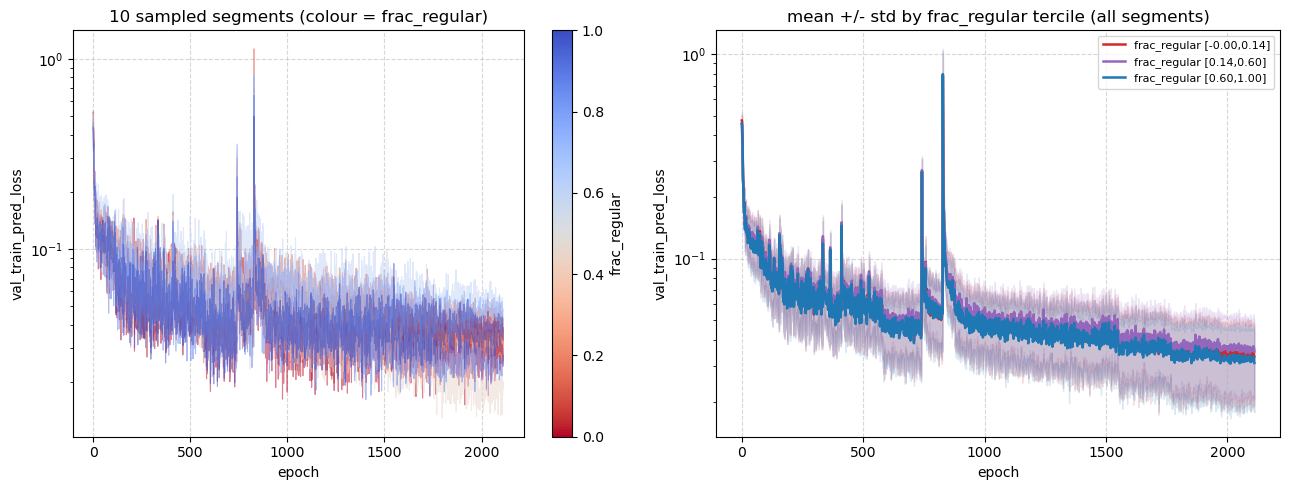

In [59]:
merged = load_segment_progress(save_dir_path, train_seg_id_df)

# two-panel plot: left = sampled individual segment curves (colour = frac_regular),
# right = mean±std by frac_regular tercile over ALL segments
fig = plot_segment_progress(merged,
                            loss_col='val_train_pred_loss',
                            n_sample_lines=10,       # how many individual curves on the left
                            color_by='frac_regular', # continuous colour in [0,1]
                            n_bins=3,                # terciles: chaotic / mixed / regular
                            log_y=True)

# text summary: final-epoch loss stats per tercile
summarise_segment_progress(merged, color_by='frac_regular', n_bins=3)

In [49]:

def Autoregressive_Handoff_Inference_Protocol_general(
    mapping_net,
    inverse_net,
    x_obs,
    u_obs,
    t_obs,
    t_min,
    t_max,
    Tmax,
    query_times,
    query_indices,
    device,
    n,
):
    """
    General-n Autoregressive Handoff Inference Protocol.
 
    Args:
        mapping_net: trained general-n MappingNet. Expects (q, p, t) with
                     q, p of shape (batch, n) and t of shape (batch, 1).
        inverse_net: trained general-n InverseNet, same shape convention.
        x_obs: (n,) tensor, observed q vector.
        u_obs: (n,) tensor, observed p vector.
        t_obs: float, observation time.
        t_min: float, start of prediction interval.
        t_max: float, end of prediction interval.
        Tmax: float, maximum normalized temporal horizon.
        query_times: 1D numpy array of query times (excluding t_obs).
        query_indices: list of ints, original indices for query_times.
        device: torch device.
        n: int, number of degrees of freedom.
 
    Returns:
        pred_dict: dict mapping original index -> (q_pred, p_pred), each an
                   (n,) float32 numpy array.
        forward_pass_count: dict with 'mapping_net' and 'inverse_net' counts.
    """
    # -------- Input validation --------
    if Tmax is None or Tmax <= 0:
        raise ValueError(f"Tmax must be a positive number, got {Tmax}")
    if not isinstance(query_indices, list):
        raise ValueError(f"query_indices must be a list, got {type(query_indices)}")
    if len(query_indices) != len(query_times):
        raise ValueError(
            f"query_indices and query_times must have the same length, "
            f"got {len(query_indices)} and {len(query_times)}"
        )
    if x_obs.dim() != 1 or u_obs.dim() != 1:
        raise ValueError(
            f"x_obs and u_obs must be 1D (n,) tensors, got dims "
            f"{x_obs.dim()} and {u_obs.dim()}"
        )
    if x_obs.shape[-1] != n or u_obs.shape[-1] != n:
        raise ValueError(
            f"x_obs and u_obs must have length n={n}, got "
            f"{x_obs.shape[-1]} and {u_obs.shape[-1]}"
        )
    if hasattr(mapping_net, "n") and mapping_net.n != n:
        raise ValueError(f"mapping_net.n={mapping_net.n} does not match n={n}")
    if hasattr(inverse_net, "n") and inverse_net.n != n:
        raise ValueError(f"inverse_net.n={inverse_net.n} does not match n={n}")
 
    forward_pass_count = {'mapping_net': 0, 'inverse_net': 0}
    pred_dict = {}
 
    if len(query_indices) == 0:
        return pred_dict, forward_pass_count
 
    # -------- Case 1: Direct Prediction --------
    if (t_max - t_min) <= Tmax:
        t_rel_obs = torch.tensor([[t_obs - t_min]], device=device, dtype=torch.float32)  # (1,1)
        Q, P, _ = mapping_net(x_obs.unsqueeze(0), u_obs.unsqueeze(0), t_rel_obs)          # (1,n)
        forward_pass_count['mapping_net'] += 1
 
        t_rel_query = torch.tensor(query_times - t_min, device=device,
                                   dtype=torch.float32).unsqueeze(1)                       # (Nq,1)
        Q_full = Q.expand(len(query_indices), n)                                           # (Nq,n)
        P_full = P.expand(len(query_indices), n)
        x_pred_query, u_pred_query, _ = inverse_net(Q_full, P_full, t_rel_query)           # (Nq,n)
        forward_pass_count['inverse_net'] += 1
 
        for j, idx in enumerate(query_indices):
            pred_dict[idx] = (
                x_pred_query[j].detach().cpu().numpy(),
                u_pred_query[j].detach().cpu().numpy(),
            )
        return pred_dict, forward_pass_count
 
    # -------- Case 2: Autoregressive Propagation --------
 
    # === Phase 1: Forward Propagation ===
    fwd = [(idx, query_times[j]) for j, idx in enumerate(query_indices) if query_times[j] > t_obs]
    if fwd:
        fwd_indices, fwd_times = zip(*fwd)
        fwd_indices = list(fwd_indices)
        fwd_times = np.array(fwd_times)
 
        K_fwd = int(np.ceil((t_max - t_obs) / Tmax - 1e-9))
        K_fwd = max(K_fwd, 1)
 
        q_curr = x_obs.clone()  # (n,)
        p_curr = u_obs.clone()  # (n,)
        t_curr = t_obs
 
        for k in range(K_fwd):
            T_start_k = t_curr
            T_end_k = min(t_curr + Tmax, t_max)
            if k == K_fwd - 1:
                T_end_k = t_max
 
            if k < K_fwd - 1:
                I_k_query = [(idx, ft) for idx, ft in zip(fwd_indices, fwd_times)
                             if T_start_k <= ft < T_end_k]
            else:
                I_k_query = [(idx, ft) for idx, ft in zip(fwd_indices, fwd_times)
                             if T_start_k <= ft <= T_end_k]
 
            need_boundary = (k < K_fwd - 1)
 
            t_rel_list = [ft - T_start_k for _, ft in I_k_query]
            if need_boundary:
                t_rel_list.append(T_end_k - T_start_k)
            if len(t_rel_list) == 0:
                continue
 
            t_rel_k = torch.tensor(t_rel_list, device=device, dtype=torch.float32).unsqueeze(1)  # (Nt,1)
 
            Q_k, P_k, _ = mapping_net(
                q_curr.unsqueeze(0), p_curr.unsqueeze(0),
                torch.tensor([[0.0]], device=device, dtype=torch.float32),  # (1,1)
            )
            forward_pass_count['mapping_net'] += 1
 
            Q_full_k = Q_k.expand(t_rel_k.shape[0], n)
            P_full_k = P_k.expand(t_rel_k.shape[0], n)
 
            q_hat_k, p_hat_k, _ = inverse_net(Q_full_k, P_full_k, t_rel_k)  # (Nt,n)
            forward_pass_count['inverse_net'] += 1
 
            for j, (idx, _) in enumerate(I_k_query):
                pred_dict[idx] = (
                    q_hat_k[j].detach().cpu().numpy(),
                    p_hat_k[j].detach().cpu().numpy(),
                )
 
            if need_boundary:
                q_curr = q_hat_k[-1].detach()  # (n,)
                p_curr = p_hat_k[-1].detach()  # (n,)
                t_curr = T_end_k
 
    # === Phase 2: Backward Propagation ===
    bwd = [(idx, query_times[j]) for j, idx in enumerate(query_indices) if query_times[j] < t_obs]
    if bwd:
        bwd_indices, bwd_times = zip(*bwd)
        bwd_indices = list(bwd_indices)
        bwd_times = np.array(bwd_times)
 
        K_bwd = int(np.ceil((t_obs - t_min) / Tmax - 1e-9))
        K_bwd = max(K_bwd, 1)
 
        q_curr = x_obs.clone()
        p_curr = u_obs.clone()
        t_curr = t_obs
 
        for k in range(K_bwd):
            T_start_k = max(t_curr - Tmax, t_min)
            T_end_k = t_curr
            if k == K_bwd - 1:
                T_start_k = t_min
 
            if k < K_bwd - 1:
                I_k_query = [(idx, bt) for idx, bt in zip(bwd_indices, bwd_times)
                             if T_start_k < bt <= T_end_k]
            else:
                I_k_query = [(idx, bt) for idx, bt in zip(bwd_indices, bwd_times)
                             if T_start_k <= bt <= T_end_k]
 
            need_boundary = (k < K_bwd - 1)
 
            t_rel_list = []
            if need_boundary:
                t_rel_list.append(0.0)
            t_rel_list.extend([bt - T_start_k for _, bt in I_k_query])
            if len(t_rel_list) == 0:
                continue
 
            t_rel_k = torch.tensor(t_rel_list, device=device, dtype=torch.float32).unsqueeze(1)  # (Nt,1)
 
            t_rel_obs_in_window = T_end_k - T_start_k
            Q_k, P_k, _ = mapping_net(
                q_curr.unsqueeze(0), p_curr.unsqueeze(0),
                torch.tensor([[t_rel_obs_in_window]], device=device, dtype=torch.float32),  # (1,1)
            )
            forward_pass_count['mapping_net'] += 1
 
            Q_full_k = Q_k.expand(t_rel_k.shape[0], n)
            P_full_k = P_k.expand(t_rel_k.shape[0], n)
 
            q_hat_k, p_hat_k, _ = inverse_net(Q_full_k, P_full_k, t_rel_k)  # (Nt,n)
            forward_pass_count['inverse_net'] += 1
 
            offset = 1 if need_boundary else 0
            for j, (idx, _) in enumerate(I_k_query):
                pred_dict[idx] = (
                    q_hat_k[offset + j].detach().cpu().numpy(),
                    p_hat_k[offset + j].detach().cpu().numpy(),
                )
 
            if need_boundary:
                q_curr = q_hat_k[0].detach()  # (n,)
                p_curr = p_hat_k[0].detach()  # (n,)
                t_curr = T_start_k
 
    missing = [idx for idx in query_indices if idx not in pred_dict]
    if missing:
        raise RuntimeError(
            f"Autoregressive_Handoff_Inference_Protocol_general failed to produce "
            f"predictions for indices {missing}. This is likely a floating point "
            f"boundary issue. t_obs={t_obs}, t_min={t_min}, t_max={t_max}, Tmax={Tmax}"
        )
    return pred_dict, forward_pass_count
 
 
def Batched_Autoregressive_Handoff_Inference_Protocol_general(
    mapping_net,
    inverse_net,
    x_obs,
    u_obs,
    t_obs,
    t_min,
    t_max,
    Tmax,
    query_times,
    query_indices,
    device,
    n,
):
    """
    General-n Batched Autoregressive Handoff Inference Protocol.
 
    All trajectories share the same time structure (same t values, same obs index).
 
    Args:
        x_obs: (N_traj, n) tensor, observed q vectors.
        u_obs: (N_traj, n) tensor, observed p vectors.
        (remaining args as in the single-trajectory version)
        n: int, number of degrees of freedom.
 
    Returns:
        x_pred_all: (N_traj, N_query, n) tensor of q predictions at query times.
        u_pred_all: (N_traj, N_query, n) tensor of p predictions at query times.
        forward_pass_count: dict with 'mapping_net' and 'inverse_net' counts.
    """
    if Tmax is None or Tmax <= 0:
        raise ValueError(f"Tmax must be a positive number, got {Tmax}")
    if not isinstance(query_indices, list):
        raise ValueError(f"query_indices must be a list, got {type(query_indices)}")
    if len(query_indices) != len(query_times):
        raise ValueError(
            f"query_indices and query_times must have the same length, "
            f"got {len(query_indices)} and {len(query_times)}"
        )
    if x_obs.dim() != 2 or u_obs.dim() != 2:
        raise ValueError(
            f"x_obs and u_obs must be 2D (N_traj, n) tensors, got dims "
            f"{x_obs.dim()} and {u_obs.dim()}"
        )
    if x_obs.shape[0] != u_obs.shape[0]:
        raise ValueError(
            f"x_obs and u_obs must have the same N_traj, got "
            f"{x_obs.shape[0]} and {u_obs.shape[0]}"
        )
    if x_obs.shape[1] != n or u_obs.shape[1] != n:
        raise ValueError(
            f"x_obs and u_obs must have DOF dim n={n}, got "
            f"{x_obs.shape[1]} and {u_obs.shape[1]}"
        )
    if hasattr(mapping_net, "n") and mapping_net.n != n:
        raise ValueError(f"mapping_net.n={mapping_net.n} does not match n={n}")
    if hasattr(inverse_net, "n") and inverse_net.n != n:
        raise ValueError(f"inverse_net.n={inverse_net.n} does not match n={n}")
 
    N_traj = x_obs.shape[0]
    N_query = len(query_indices)
    forward_pass_count = {'mapping_net': 0, 'inverse_net': 0}
 
    x_pred_all = torch.empty(N_traj, N_query, n, device=device, dtype=torch.float32)
    u_pred_all = torch.empty(N_traj, N_query, n, device=device, dtype=torch.float32)
 
    if N_query == 0:
        return x_pred_all, u_pred_all, forward_pass_count
 
    # -------- Case 1: Direct Prediction --------
    if (t_max - t_min) <= Tmax:
        t_rel_obs = torch.full((N_traj, 1), float(t_obs - t_min),
                               device=device, dtype=torch.float32)  # (N_traj,1)
        Q, P, _ = mapping_net(x_obs, u_obs, t_rel_obs)              # (N_traj,n)
        forward_pass_count['mapping_net'] += 1
 
        # traj-major, query-minor flatten
        Q_full = Q.repeat_interleave(N_query, dim=0)               # (N_traj*Nq, n)
        P_full = P.repeat_interleave(N_query, dim=0)
 
        t_rel_query = torch.tensor(query_times - t_min, device=device, dtype=torch.float32)  # (Nq,)
        t_rel_full = t_rel_query.repeat(N_traj).unsqueeze(1)       # (N_traj*Nq, 1)
 
        x_pred_flat, u_pred_flat, _ = inverse_net(Q_full, P_full, t_rel_full)  # (N_traj*Nq, n)
        forward_pass_count['inverse_net'] += 1
 
        x_pred_all = x_pred_flat.reshape(N_traj, N_query, n)
        u_pred_all = u_pred_flat.reshape(N_traj, N_query, n)
        return x_pred_all, u_pred_all, forward_pass_count
 
    # -------- Case 2: Autoregressive Propagation --------
 
    # === Phase 1: Forward Propagation ===
    fwd_positions = [j for j, idx in enumerate(query_indices) if query_times[j] > t_obs]
    if len(fwd_positions) > 0:
        K_fwd = int(np.ceil((t_max - t_obs) / Tmax - 1e-9))
        K_fwd = max(K_fwd, 1)
        q_curr = x_obs.clone()  # (N_traj, n)
        p_curr = u_obs.clone()
        t_curr = t_obs
 
        for k in range(K_fwd):
            T_start_k = t_curr
            T_end_k = min(t_curr + Tmax, t_max)
            if k == K_fwd - 1:
                T_end_k = t_max
            if k < K_fwd - 1:
                seg_query_positions = [j for j in fwd_positions
                                       if T_start_k <= query_times[j] < T_end_k]
            else:
                seg_query_positions = [j for j in fwd_positions
                                       if T_start_k <= query_times[j] <= T_end_k]
 
            need_boundary = (k < K_fwd - 1)
 
            t_rel_list = [query_times[j] - T_start_k for j in seg_query_positions]
            if need_boundary:
                t_rel_list.append(T_end_k - T_start_k)
 
            N_times = len(t_rel_list)
            if N_times == 0:
                continue
 
            t_rel_k = torch.tensor(t_rel_list, device=device, dtype=torch.float32)  # (Nt,)
 
            t_zero = torch.zeros(N_traj, 1, device=device, dtype=torch.float32)     # (N_traj,1)
            Q_k, P_k, _ = mapping_net(q_curr, p_curr, t_zero)                       # (N_traj,n)
            forward_pass_count['mapping_net'] += 1
 
            Q_full_k = Q_k.repeat_interleave(N_times, dim=0)        # (N_traj*Nt, n)
            P_full_k = P_k.repeat_interleave(N_times, dim=0)
            t_rel_full_k = t_rel_k.repeat(N_traj).unsqueeze(1)      # (N_traj*Nt, 1)
 
            q_hat_flat, p_hat_flat, _ = inverse_net(Q_full_k, P_full_k, t_rel_full_k)
            forward_pass_count['inverse_net'] += 1
 
            q_hat_k = q_hat_flat.reshape(N_traj, N_times, n)
            p_hat_k = p_hat_flat.reshape(N_traj, N_times, n)
 
            for local_j, global_j in enumerate(seg_query_positions):
                x_pred_all[:, global_j, :] = q_hat_k[:, local_j, :]
                u_pred_all[:, global_j, :] = p_hat_k[:, local_j, :]
 
            if need_boundary:
                q_curr = q_hat_k[:, -1, :].detach()  # (N_traj, n)
                p_curr = p_hat_k[:, -1, :].detach()
                t_curr = T_end_k
 
    # === Phase 2: Backward Propagation ===
    bwd_positions = [j for j, idx in enumerate(query_indices) if query_times[j] < t_obs]
    if len(bwd_positions) > 0:
        K_bwd = int(np.ceil((t_obs - t_min) / Tmax - 1e-9))
        K_bwd = max(K_bwd, 1)
        q_curr = x_obs.clone()  # (N_traj, n)
        p_curr = u_obs.clone()
        t_curr = t_obs
 
        for k in range(K_bwd):
            T_start_k = max(t_curr - Tmax, t_min)
            T_end_k = t_curr
            if k == K_bwd - 1:
                T_start_k = t_min
 
            if k < K_bwd - 1:
                seg_query_positions = [j for j in bwd_positions
                                       if T_start_k < query_times[j] <= T_end_k]
            else:
                seg_query_positions = [j for j in bwd_positions
                                       if T_start_k <= query_times[j] <= T_end_k]
 
            need_boundary = (k < K_bwd - 1)
 
            t_rel_list = []
            if need_boundary:
                t_rel_list.append(0.0)
            t_rel_list.extend([query_times[j] - T_start_k for j in seg_query_positions])
 
            N_times = len(t_rel_list)
            if N_times == 0:
                continue
 
            t_rel_k = torch.tensor(t_rel_list, device=device, dtype=torch.float32)  # (Nt,)
 
            t_rel_obs_in_window = T_end_k - T_start_k
            t_obs_window = torch.full((N_traj, 1), float(t_rel_obs_in_window),
                                      device=device, dtype=torch.float32)           # (N_traj,1)
            Q_k, P_k, _ = mapping_net(q_curr, p_curr, t_obs_window)                 # (N_traj,n)
            forward_pass_count['mapping_net'] += 1
 
            Q_full_k = Q_k.repeat_interleave(N_times, dim=0)
            P_full_k = P_k.repeat_interleave(N_times, dim=0)
            t_rel_full_k = t_rel_k.repeat(N_traj).unsqueeze(1)
 
            q_hat_flat, p_hat_flat, _ = inverse_net(Q_full_k, P_full_k, t_rel_full_k)
            forward_pass_count['inverse_net'] += 1
 
            q_hat_k = q_hat_flat.reshape(N_traj, N_times, n)
            p_hat_k = p_hat_flat.reshape(N_traj, N_times, n)
 
            offset = 1 if need_boundary else 0
            for local_j, global_j in enumerate(seg_query_positions):
                x_pred_all[:, global_j, :] = q_hat_k[:, offset + local_j, :]
                u_pred_all[:, global_j, :] = p_hat_k[:, offset + local_j, :]
 
            if need_boundary:
                q_curr = q_hat_k[:, 0, :].detach()  # (N_traj, n)
                p_curr = p_hat_k[:, 0, :].detach()
                t_curr = T_start_k
 
    return x_pred_all, u_pred_all, forward_pass_count





POS_COLS = ("x", "y")
MOM_COLS = ("px", "py")


def build_omega_general(n, device=None, dtype=None):
    """
    Symplectic form for n degrees of freedom, in the grouped ordering
    z = (q_1, ..., q_n, p_1, ..., p_n) fixed by the paper:

        Omega = [[ 0,   I_n ],
                 [-I_n, 0   ]]      shape (2n, 2n)

    Reduces to [[0, 1], [-1, 0]] at n = 1.
    """
    I = torch.eye(n, device=device, dtype=dtype)
    Z = torch.zeros(n, n, device=device, dtype=dtype)
    return torch.cat([torch.cat([Z, I], dim=1),
                      torch.cat([-I, Z], dim=1)], dim=0)


def compute_jacobian_functional_general(model, x, u, t, n):
    """
    Compute the 2n x 2n Jacobian of a general-n network using
    torch.autograd.functional.jacobian, one sample at a time.

    Row/column ordering is the grouped convention z = (q_1..q_n, p_1..p_n):
        M[i, j] = d z'_i / d z_j
        rows    0..n-1   -> Q,   rows    n..2n-1 -> P
        columns 0..n-1   -> q,   columns n..2n-1 -> p

    IMPORTANT: the HJL layers compute their shear terms with
    create_graph=self.training. If `model` is in eval() mode the generating
    function gradients are detached, the off-diagonal blocks of M come out
    exactly zero, and M collapses to a (still symplectic, hence vacuously
    passing) diagonal scaling. Callers must run this in train() mode; the
    orchestrator below enforces that.

    Args:
        model: network taking (q, p, t) with q, p of shape (batch, n) and
               t of shape (batch, 1), returning (Q, P, t).
        x: (batch, n) tensor, coordinate-like input.
        u: (batch, n) tensor, momentum-like input.
        t: (batch, 1) tensor, time.
        n: int, number of degrees of freedom.

    Returns:
        jacobian: (2n, 2n, batch) tensor.
    """
    from torch.autograd.functional import jacobian as torch_jacobian

    if x.dim() != 2 or u.dim() != 2:
        raise ValueError(f"x and u must be 2D (batch, n) tensors, got dims {x.dim()} and {u.dim()}")
    if x.shape[1] != n or u.shape[1] != n:
        raise ValueError(f"x and u must have DOF dim n={n}, got {x.shape[1]} and {u.shape[1]}")
    if t.dim() != 2 or t.shape[1] != 1:
        raise ValueError(f"t must be a 2D (batch, 1) tensor, got shape {tuple(t.shape)}")
    if not (x.shape[0] == u.shape[0] == t.shape[0]):
        raise ValueError(
            f"batch dims must match, got {x.shape[0]}, {u.shape[0]}, {t.shape[0]}")
    if hasattr(model, "n") and model.n != n:
        raise ValueError(f"model.n={model.n} does not match n={n}")

    batch_size = x.shape[0]
    jacobians = []

    for i in range(batch_size):
        x_i = x[i:i + 1]          # (1, n)
        u_i = u[i:i + 1]          # (1, n)
        t_i = t[i:i + 1]          # (1, 1)

        # Function of (x, u) only; t is held fixed (the paper takes the
        # Jacobian at fixed segment-relative time).
        def func(x_val, u_val):
            X_final, U_final, _ = model(x_val, u_val, t_i)
            return torch.cat([X_final.reshape(-1), U_final.reshape(-1)], dim=0)   # (2n,)

        jac = torch_jacobian(func, (x_i, u_i))

        # jac[0]: d(out)/dx with shape (2n, 1, n);  jac[1]: d(out)/du likewise.
        # Explicit reshape rather than .squeeze(), which would over-collapse at n=1.
        jac_x = jac[0].reshape(2 * n, n)                       # (2n, n)
        jac_u = jac[1].reshape(2 * n, n)                       # (2n, n)

        jac_matrix = torch.cat([jac_x, jac_u], dim=1)          # (2n, 2n)
        jacobians.append(jac_matrix)

    jacobian = torch.stack(jacobians, dim=2)                   # (2n, 2n, batch)
    return jacobian


def compute_symplectic_product_general(jacobian, n):
    """
    Compute M^T Omega M for each 2n x 2n Jacobian in the batch, with
    Omega = [[0, I_n], [-I_n, 0]].

    Args:
        jacobian: (2n, 2n, batch) tensor.
        n: int, number of degrees of freedom.

    Returns:
        result: (2n, 2n, batch) tensor, each slice being M^T Omega M.
    """
    if jacobian.dim() != 3:
        raise ValueError(f"jacobian must be 3D (2n, 2n, batch), got dim {jacobian.dim()}")
    if jacobian.shape[0] != 2 * n or jacobian.shape[1] != 2 * n:
        raise ValueError(
            f"jacobian must be (2n, 2n, batch) with n={n} -> "
            f"({2*n}, {2*n}, batch), got {tuple(jacobian.shape)}")

    batch_size = jacobian.shape[2]
    device = jacobian.device
    dtype = jacobian.dtype

    Omega = build_omega_general(n, device=device, dtype=dtype)      # (2n, 2n)

    M = jacobian.permute(2, 0, 1)                                   # (batch, 2n, 2n)
    M_T = M.transpose(1, 2)                                         # (batch, 2n, 2n)
    Omega_batch = Omega.unsqueeze(0).expand(batch_size, -1, -1)

    Omega_M = torch.bmm(Omega_batch, M)                             # (batch, 2n, 2n)
    result_batch = torch.bmm(M_T, Omega_M)                          # (batch, 2n, 2n)

    result = result_batch.permute(1, 2, 0)                          # (2n, 2n, batch)
    return result


def test_canonical_transformation_on_trajectory_general(
    get_data_from_trajectory_id_function,
    compute_jacobian_functional_function,
    compute_symplectic_product_function,
    test_id_df,
    test_df,
    trajectory_id,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    tolerance=1e-5,
    verbose=True,
):
    """
    General-n symplecticity diagnostic on a single trajectory.

    Partitions the trajectory into segments of length Tmax and, at every
    observation, computes the 2n x 2n Jacobian of MappingNet w.r.t. (q, p) and
    of InverseNet w.r.t. (Q, P), both at the segment-relative time, then
    evaluates the residual ||M^T Omega M - Omega||_max per point.

    Both networks are forced into train() mode for the duration and restored
    on exit: the HJL shear gradients are built with create_graph=self.training,
    so in eval() mode the off-diagonal Jacobian blocks are identically zero and
    the residual is vacuously zero.

    Returns:
        results: dict with per-point residuals and summary statistics for both
                 networks (same keys as the n=1 version, plus 'n').
    """
    if Tmax is None or Tmax <= 0:
        raise ValueError(f"Tmax must be a positive number, got {Tmax}")
    if len(pos_cols) != n:
        raise ValueError(f"pos_cols must have n={n} entries, got {len(pos_cols)}: {pos_cols}")
    if len(mom_cols) != n:
        raise ValueError(f"mom_cols must have n={n} entries, got {len(mom_cols)}: {mom_cols}")
    if hasattr(mapping_net, "n") and mapping_net.n != n:
        raise ValueError(f"mapping_net.n={mapping_net.n} does not match n={n}")
    if hasattr(inverse_net, "n") and inverse_net.n != n:
        raise ValueError(f"inverse_net.n={inverse_net.n} does not match n={n}")

    test_trajectory_data = get_data_from_trajectory_id_function(
        test_id_df, test_df, trajectory_ids=trajectory_id)

    missing = [c for c in list(pos_cols) + list(mom_cols) + ['t']
               if c not in test_trajectory_data.columns]
    if missing:
        raise ValueError(f"columns missing from trajectory data: {missing}")

    x = torch.as_tensor(test_trajectory_data[list(pos_cols)].to_numpy(dtype=np.float32),
                        device=device)                                   # (T, n)
    u = torch.as_tensor(test_trajectory_data[list(mom_cols)].to_numpy(dtype=np.float32),
                        device=device)                                   # (T, n)
    t = torch.as_tensor(test_trajectory_data['t'].to_numpy(dtype=np.float32),
                        device=device)                                   # (T,)

    if x.dim() != 2 or u.dim() != 2 or t.dim() != 1:
        raise ValueError(
            f"x, u must be 2-dimensional and t 1-dimensional, got dims "
            f"{x.dim()}, {u.dim()}, {t.dim()}")
    if x.shape[1] != n or u.shape[1] != n:
        raise ValueError(f"x, u must have DOF dim n={n}, got {x.shape[1]}, {u.shape[1]}")

    t_np = t.detach().cpu().numpy()
    t_max = t_np[-1]

    # Build segments (anchored at absolute zero, as in the n=1 version)
    num_segments = int(np.ceil(t_max / Tmax - 1e-9))
    num_segments = max(num_segments, 1)

    mapping_jacobians = []
    inverse_jacobians = []

    # ---- force train() so that create_graph=True inside the HJL shear grads ----
    mapping_was_training = mapping_net.training
    inverse_was_training = inverse_net.training
    try:
        mapping_net.train()
        inverse_net.train()

        for seg_idx in range(num_segments):
            t_start = seg_idx * Tmax
            t_end = min((seg_idx + 1) * Tmax, t_max)
            if seg_idx == num_segments - 1:
                t_end = t_max

            if seg_idx == 0:
                seg_mask = (t_np >= t_start) & (t_np <= t_end)
            else:
                seg_mask = (t_np > t_start) & (t_np <= t_end)

            seg_indices = np.where(seg_mask)[0]

            if len(seg_indices) == 0:
                continue

            x_seg = x[seg_indices]                                       # (S, n)
            u_seg = u[seg_indices]                                       # (S, n)
            t_seg_relative = (t[seg_indices] - t_start).unsqueeze(1)     # (S, 1)

            jac_mapping = compute_jacobian_functional_function(
                mapping_net, x=x_seg, u=u_seg, t=t_seg_relative, n=n)
            mapping_jacobians.append(jac_mapping)

            Q_seg, P_seg, _ = mapping_net(x_seg, u_seg, t_seg_relative)

            jac_inverse = compute_jacobian_functional_function(
                inverse_net, x=Q_seg.detach(), u=P_seg.detach(),
                t=t_seg_relative, n=n)
            inverse_jacobians.append(jac_inverse)
    finally:
        # inverse_net shares its modules with mapping_net, so restore the
        # inverse first and let mapping_net (the owner) have the last word.
        inverse_net.train(inverse_was_training)
        mapping_net.train(mapping_was_training)

    all_mapping_jac = torch.cat(mapping_jacobians, dim=2)                # (2n, 2n, N)
    all_inverse_jac = torch.cat(inverse_jacobians, dim=2)

    mapping_symplectic = compute_symplectic_product_function(all_mapping_jac, n)
    inverse_symplectic = compute_symplectic_product_function(all_inverse_jac, n)

    batch_size = mapping_symplectic.shape[2]
    device_sym = mapping_symplectic.device
    dtype_sym = mapping_symplectic.dtype

    Omega = build_omega_general(n, device=device_sym, dtype=dtype_sym)   # (2n, 2n)

    diff_mapping = torch.abs(mapping_symplectic - Omega.unsqueeze(-1))
    mapping_residuals = diff_mapping.amax(dim=(0, 1))

    diff_inverse = torch.abs(inverse_symplectic - Omega.unsqueeze(-1))
    inverse_residuals = diff_inverse.amax(dim=(0, 1))

    mapping_residuals_np = mapping_residuals.detach().cpu().numpy()
    inverse_residuals_np = inverse_residuals.detach().cpu().numpy()

    def compute_residual_stats(residuals, name):
        return {
            'mean': np.mean(residuals),
            'std': np.std(residuals, ddof=1) if len(residuals) > 1 else 0.0,
            'median': np.median(residuals),
            'max': np.max(residuals),
            'min': np.min(residuals),
            'q25': np.percentile(residuals, 25),
            'q75': np.percentile(residuals, 75),
            'n_failing': int(np.sum(residuals > tolerance)),
            'n_total': len(residuals),
            'fraction_passing': float(np.mean(residuals <= tolerance)),
        }

    mapping_stats = compute_residual_stats(mapping_residuals_np, 'mapping')
    inverse_stats = compute_residual_stats(inverse_residuals_np, 'inverse')

    if verbose:
        print(f"=== Canonical Transformation Test — Trajectory {trajectory_id} ===")
        print(f"(n={n}, Jacobians are {2*n}x{2*n}, {num_segments} segment(s), "
              f"{batch_size} total points, tolerance={tolerance:.1e})\n")

        print("MappingNet: d(Q,P)/d(q,p)")
        if mapping_stats['n_failing'] == 0:
            print(f"  ✓ All {batch_size} points pass (max residual: {mapping_stats['max']:.2e})")
        else:
            print(f"  ✗ {mapping_stats['n_failing']}/{batch_size} points fail "
                  f"({mapping_stats['fraction_passing']*100:.1f}% pass)")
        print(f"  Residual max|M^T Ω M - Ω| per point:")
        print(f"    Mean:   {mapping_stats['mean']:.2e} (std={mapping_stats['std']:.2e})")
        print(f"    Median: {mapping_stats['median']:.2e} [IQR: {mapping_stats['q25']:.2e}, {mapping_stats['q75']:.2e}]")
        print(f"    Min:    {mapping_stats['min']:.2e}")
        print(f"    Max:    {mapping_stats['max']:.2e}")

        print(f"\nInverseNet: d(q,p)/d(Q,P)")
        if inverse_stats['n_failing'] == 0:
            print(f"  ✓ All {batch_size} points pass (max residual: {inverse_stats['max']:.2e})")
        else:
            print(f"  ✗ {inverse_stats['n_failing']}/{batch_size} points fail "
                  f"({inverse_stats['fraction_passing']*100:.1f}% pass)")
        print(f"  Residual max|M^T Ω M - Ω| per point:")
        print(f"    Mean:   {inverse_stats['mean']:.2e} (std={inverse_stats['std']:.2e})")
        print(f"    Median: {inverse_stats['median']:.2e} [IQR: {inverse_stats['q25']:.2e}, {inverse_stats['q75']:.2e}]")
        print(f"    Min:    {inverse_stats['min']:.2e}")
        print(f"    Max:    {inverse_stats['max']:.2e}")

        print("\n=== Table row (Task = trajectory {}) ===".format(trajectory_id))
        print(f"  M  max    = {mapping_stats['max']:.2e}")
        print(f"  M  median = {mapping_stats['median']:.2e}")
        print(f"  M^-1 max    = {inverse_stats['max']:.2e}")
        print(f"  M^-1 median = {inverse_stats['median']:.2e}")
        print("  LaTeX: "
              f"{mapping_stats['max']:.2e} & {mapping_stats['median']:.2e} & "
              f"{inverse_stats['max']:.2e} & {inverse_stats['median']:.2e} \\\\")

    results = {
        'mapping_residuals': mapping_residuals_np,
        'inverse_residuals': inverse_residuals_np,
        'mapping_stats': mapping_stats,
        'inverse_stats': inverse_stats,
        'mapping_symplectic': mapping_symplectic,
        'inverse_symplectic': inverse_symplectic,
        't': t_np,
        'trajectory_id': trajectory_id,
        'tolerance': tolerance,
        'num_segments': num_segments,
        'n_points': batch_size,
        'n': n,
    }

    return results
 


def prediction_loss_euclidean_general(
    x_pred: torch.Tensor,
    u_pred: torch.Tensor,
    X_labels: torch.Tensor,
    U_labels: torch.Tensor,
    n: int,
) -> torch.Tensor:
    """
    Prediction loss: mean over prediction times of the Euclidean distance in the
    2n-dimensional phase space,

        d_t = sqrt( sum_i (q_hat_{t,i} - q_{t,i})^2 + sum_i (p_hat_{t,i} - p_{t,i})^2 )

    At n = 1 with (..., 1)-shaped inputs the sum over the DOF axis is a
    single-element sum, so this reduces exactly (bitwise) to the n = 1 function
        sqrt((x_pred - X_labels)^2 + (u_pred - U_labels)^2).mean()
    evaluated on the corresponding (...,)-shaped tensors.

    Args:
        x_pred:   (..., n) predicted positions
        u_pred:   (..., n) predicted momenta
        X_labels: (..., n) ground-truth positions
        U_labels: (..., n) ground-truth momenta
        n: int, number of degrees of freedom (last axis).

    Returns:
        loss: scalar tensor, mean Euclidean phase-space distance.
    """
    if not (x_pred.shape == u_pred.shape == X_labels.shape == U_labels.shape):
        raise ValueError(
            f"x_pred, u_pred, X_labels, U_labels must share a shape, got "
            f"{tuple(x_pred.shape)}, {tuple(u_pred.shape)}, "
            f"{tuple(X_labels.shape)}, {tuple(U_labels.shape)}")
    if x_pred.dim() < 1 or x_pred.shape[-1] != n:
        raise ValueError(
            f"last axis must be the DOF axis of size n={n}, got shape {tuple(x_pred.shape)}")

    euclidean_distances = torch.sqrt(
        ((x_pred - X_labels) ** 2).sum(dim=-1)
        + ((u_pred - U_labels) ** 2).sum(dim=-1)
    )
    return torch.mean(euclidean_distances)


def test_model_all_observations_all_trajectories_general(
    get_data_from_trajectory_id_function,
    prediction_loss_function,
    test_id_df,
    test_df,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    bootstrap_B=10000,
    confidence_level=0.95,
    normalize_by_energy=True,
    verbose=True,
):
    """
    General-n evaluation of all test trajectories from every possible single
    observation point.

    Identical in statistics and aggregation to the n = 1 version; the only change
    is that phase-space quantities carry a trailing DOF axis of size n, and the
    batched inference call is the general-n protocol.

    `prediction_loss_function` must accept
        (x_pred, u_pred, X_labels, U_labels, n)
    by keyword, with the four tensors of shape (N_obs, n), and return a scalar.

    Returns:
        results: dict, same keys as the n = 1 version plus 'n'.
    """
    from scipy.stats import bootstrap

    if Tmax is None or Tmax <= 0:
        raise ValueError(f"Tmax must be a positive number, got {Tmax}")

    if normalize_by_energy and 'energy' not in test_id_df.columns:
        raise ValueError("test_id_df must contain an 'energy' column when normalize_by_energy=True")

    if len(pos_cols) != n:
        raise ValueError(f"pos_cols must have n={n} entries, got {len(pos_cols)}: {pos_cols}")
    if len(mom_cols) != n:
        raise ValueError(f"mom_cols must have n={n} entries, got {len(mom_cols)}: {mom_cols}")
    if hasattr(mapping_net, "n") and mapping_net.n != n:
        raise ValueError(f"mapping_net.n={mapping_net.n} does not match n={n}")
    if hasattr(inverse_net, "n") and inverse_net.n != n:
        raise ValueError(f"inverse_net.n={inverse_net.n} does not match n={n}")

    trajectory_ids = test_id_df['trajectory_id'].values.astype(int)
    N_traj = len(trajectory_ids)

    if normalize_by_energy:
        energies = test_id_df.set_index('trajectory_id').loc[trajectory_ids, 'energy'].values.astype(np.float64)
        if np.any(energies <= 1e-12):
            raise ValueError("Energy normalization by sqrt(E) requires positive nonzero energies.")
        sqrt_energies = np.sqrt(energies)
    else:
        energies = test_id_df.set_index('trajectory_id').loc[trajectory_ids, 'energy'].values.astype(np.float64) if 'energy' in test_id_df.columns else np.full(N_traj, np.nan)
        sqrt_energies = None

    # Load all trajectories and validate shared time structure
    all_x = []
    all_u = []
    ref_t = None

    for idx, row_data in test_id_df.iterrows():
        trajectory_id = int(row_data['trajectory_id'])
        test_trajectory_data = get_data_from_trajectory_id_function(
            test_id_df, test_df, trajectory_ids=trajectory_id)

        missing = [c for c in list(pos_cols) + list(mom_cols) + ['t']
                   if c not in test_trajectory_data.columns]
        if missing:
            raise ValueError(f"Trajectory {trajectory_id}: columns missing: {missing}")

        x_i = torch.as_tensor(test_trajectory_data[list(pos_cols)].to_numpy(dtype=np.float32),
                              device=device)                                   # (T, n)
        u_i = torch.as_tensor(test_trajectory_data[list(mom_cols)].to_numpy(dtype=np.float32),
                              device=device)                                   # (T, n)
        t_i = torch.as_tensor(test_trajectory_data['t'].to_numpy(dtype=np.float32),
                              device=device)                                   # (T,)

        if x_i.dim() != 2 or u_i.dim() != 2 or t_i.dim() != 1:
            raise ValueError(
                f"Trajectory {trajectory_id}: x, u must be 2D (T, n) and t 1D, got dims "
                f"{x_i.dim()}, {u_i.dim()}, {t_i.dim()}")
        if x_i.shape[1] != n or u_i.shape[1] != n:
            raise ValueError(
                f"Trajectory {trajectory_id}: DOF dim must be n={n}, got "
                f"{x_i.shape[1]} and {u_i.shape[1]}")

        if ref_t is None:
            ref_t = t_i
        else:
            if len(t_i) != len(ref_t):
                raise ValueError(
                    f"Trajectory {trajectory_id} has {len(t_i)} points, expected {len(ref_t)}. "
                    f"All trajectories must have the same number of points for batched inference."
                )
            if not torch.allclose(t_i, ref_t, atol=1e-6):
                raise ValueError(
                    f"Trajectory {trajectory_id} has different time values. "
                    f"All trajectories must share the same time values for batched inference."
                )

        all_x.append(x_i)
        all_u.append(u_i)

    # Stack: (N_traj, N_points, n)
    x_batch = torch.stack(all_x, dim=0)
    u_batch = torch.stack(all_u, dim=0)
    t_np = ref_t.detach().cpu().numpy()
    N_obs = len(ref_t)

    all_mapping_net_calls = np.empty(N_obs, dtype=int)
    all_inverse_net_calls = np.empty(N_obs, dtype=int)

    loss_matrix = np.empty((N_obs, N_traj))

    for obs_idx in range(N_obs):
        query_indices = [i for i in range(N_obs) if i != obs_idx]
        query_times = t_np[query_indices]

        x_pred_queries, u_pred_queries, fwd_count = \
            Batched_Autoregressive_Handoff_Inference_Protocol_general(
                mapping_net=mapping_net,
                inverse_net=inverse_net,
                x_obs=x_batch[:, obs_idx, :],          # (N_traj, n)
                u_obs=u_batch[:, obs_idx, :],          # (N_traj, n)
                t_obs=t_np[obs_idx],
                t_min=t_np[0],
                t_max=t_np[-1],
                Tmax=Tmax,
                query_times=query_times,
                query_indices=query_indices,
                device=device,
                n=n,
            )

        # Assemble full predictions: (N_traj, N_obs, n)
        x_pred_full = torch.empty(N_traj, N_obs, n, device=device, dtype=torch.float32)
        u_pred_full = torch.empty(N_traj, N_obs, n, device=device, dtype=torch.float32)
        x_pred_full[:, obs_idx, :] = x_batch[:, obs_idx, :]
        u_pred_full[:, obs_idx, :] = u_batch[:, obs_idx, :]
        for j, qi in enumerate(query_indices):
            x_pred_full[:, qi, :] = x_pred_queries[:, j, :]
            u_pred_full[:, qi, :] = u_pred_queries[:, j, :]

        # Per-trajectory loss for this observation index
        for traj_i in range(N_traj):
            loss_i = prediction_loss_function(
                x_pred=x_pred_full[traj_i],            # (N_obs, n)
                u_pred=u_pred_full[traj_i],
                X_labels=x_batch[traj_i],
                U_labels=u_batch[traj_i],
                n=n,
            )
            loss_matrix[obs_idx, traj_i] = loss_i.item()

        if verbose:
            mean_this_obs = np.mean(loss_matrix[obs_idx])
            print(f"Observation index {obs_idx}/{N_obs-1}, mean loss across trajectories: {mean_this_obs:.6f}")
        all_mapping_net_calls[obs_idx] = fwd_count['mapping_net']
        all_inverse_net_calls[obs_idx] = fwd_count['inverse_net']

    # Apply energy normalization if requested
    if normalize_by_energy:
        loss_matrix_normalized = loss_matrix / sqrt_energies[np.newaxis, :]
        loss_matrix_for_stats = loss_matrix_normalized
    else:
        loss_matrix_normalized = None
        loss_matrix_for_stats = loss_matrix

    # Aggregate: median over observation choices per trajectory
    per_trajectory_median_loss = np.median(loss_matrix_for_stats, axis=0)  # (N_traj,)
    per_obs_mean_loss = np.mean(loss_matrix_for_stats, axis=1)             # (N_obs,)

    # Statistics over trajectories (the independent units)
    mean_loss = np.mean(per_trajectory_median_loss)
    std_loss = np.std(per_trajectory_median_loss, ddof=1)
    median_loss = np.median(per_trajectory_median_loss)
    q1_loss = np.percentile(per_trajectory_median_loss, 25)
    q3_loss = np.percentile(per_trajectory_median_loss, 75)
    iqr_loss = q3_loss - q1_loss

    # BCa bootstrap CI over trajectories
    bootstrap_result = bootstrap(
        data=(per_trajectory_median_loss,),
        statistic=np.mean,
        n_resamples=bootstrap_B,
        confidence_level=confidence_level,
        method='BCa',
    )
    ci_lower = bootstrap_result.confidence_interval.low
    ci_upper = bootstrap_result.confidence_interval.high

    summary_stats = {
        'mean': mean_loss,
        'std': std_loss,
        'median': median_loss,
        'q1': q1_loss,
        'q3': q3_loss,
        'iqr': iqr_loss,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper,
    }

    loss_label = 'loss / √energy' if normalize_by_energy else 'loss'

    # Forward pass count statistics
    all_total_calls = all_mapping_net_calls + all_inverse_net_calls
    forward_pass_stats = {
        'mapping_net_mean': np.mean(all_mapping_net_calls),
        'mapping_net_std': np.std(all_mapping_net_calls, ddof=1),
        'mapping_net_min': int(np.min(all_mapping_net_calls)),
        'mapping_net_max': int(np.max(all_mapping_net_calls)),
        'inverse_net_mean': np.mean(all_inverse_net_calls),
        'inverse_net_std': np.std(all_inverse_net_calls, ddof=1),
        'inverse_net_min': int(np.min(all_inverse_net_calls)),
        'inverse_net_max': int(np.max(all_inverse_net_calls)),
        'total_mean': np.mean(all_total_calls),
        'total_std': np.std(all_total_calls, ddof=1),
        'total_min': int(np.min(all_total_calls)),
        'total_max': int(np.max(all_total_calls)),
        'total_across_all_obs': int(np.sum(all_total_calls)),
    }

    # Find trajectory closest to median
    median_traj_idx = int(np.argmin(np.abs(per_trajectory_median_loss - median_loss)))
    median_representative_id = int(trajectory_ids[median_traj_idx])
    median_representative_loss = per_trajectory_median_loss[median_traj_idx]

    if verbose:
        print(f"\n=== Cross-Trajectory Statistics ===")
        print(f"Metric: {loss_label}")
        print(f"Per-trajectory summary: median across obs. choices")
        print(f"Mean of medians: {mean_loss:.6f}")
        print(f"Std of medians: {std_loss:.6f}")
        print(f"Median of medians: {median_loss:.6f}")
        print(f"IQR of medians: [{q1_loss:.6f}, {q3_loss:.6f}]")
        print(f"{confidence_level*100:.0f}% BCa CI for mean of medians (over trajectories): [{ci_lower:.6f}, {ci_upper:.6f}]")
        print(f"N_traj={N_traj}, N_obs={N_obs}, n={n}")
        print(f"\nMedian-representative trajectory: ID={median_representative_id} "
              f"(obs-median {loss_label}={median_representative_loss:.6f})")
        print(f"\n=== Forward Pass Count Statistics (over {N_obs} obs. choices, batched over {N_traj} trajectories) ===")
        print(f"MappingNet calls per obs:  mean={forward_pass_stats['mapping_net_mean']:.1f} "
              f"(std={forward_pass_stats['mapping_net_std']:.1f}), "
              f"range=[{forward_pass_stats['mapping_net_min']}, {forward_pass_stats['mapping_net_max']}]")
        print(f"InverseNet calls per obs:  mean={forward_pass_stats['inverse_net_mean']:.1f} "
              f"(std={forward_pass_stats['inverse_net_std']:.1f}), "
              f"range=[{forward_pass_stats['inverse_net_min']}, {forward_pass_stats['inverse_net_max']}]")
        print(f"Total calls per obs:       mean={forward_pass_stats['total_mean']:.1f} "
              f"(std={forward_pass_stats['total_std']:.1f}), "
              f"range=[{forward_pass_stats['total_min']}, {forward_pass_stats['total_max']}]")
        print(f"Total calls across all obs: {forward_pass_stats['total_across_all_obs']}")

    results = {
        'loss_matrix': loss_matrix,
        'loss_matrix_normalized': loss_matrix_normalized,
        'loss_matrix_for_stats': loss_matrix_for_stats,
        'per_trajectory_median_loss': per_trajectory_median_loss,
        'per_obs_mean_loss': per_obs_mean_loss,
        'summary_stats': summary_stats,
        'trajectory_ids': trajectory_ids,
        'energies': energies,
        't': t_np,
        'N_obs': N_obs,
        'N_traj': N_traj,
        'confidence_level': confidence_level,
        'normalized': normalize_by_energy,
        'forward_pass_stats': forward_pass_stats,
        'all_mapping_net_calls': all_mapping_net_calls,
        'all_inverse_net_calls': all_inverse_net_calls,
        'median_representative_id': median_representative_id,
        'median_representative_loss': median_representative_loss,
        'n': n,
    }

    return results


POS_COLS = ("x", "y")
MOM_COLS = ("px", "py")


# =====================================================================
#  Energy functions:  energy(q, p) with q, p numpy of shape (..., n) -> (...)
# =====================================================================

def make_energy_henon_heiles(lam=1.0):
    """
    H = 0.5(px^2 + py^2) + 0.5(x^2 + y^2) + lam*(x^2 y - y^3/3)   [n = 2]

    Identical to HenonHeiles.hamiltonian used to generate the data, and the
    exact Hamiltonian of build_hh_integrator's equations of motion.
    """
    def energy(q, p):
        x, y = q[..., 0], q[..., 1]
        px, py = p[..., 0], p[..., 1]
        return 0.5 * (px**2 + py**2) + 0.5 * (x**2 + y**2) \
            + lam * (x**2 * y - (1 / 3.) * y**3)
    energy.__name__ = f"henon_heiles(lam={lam})"
    return energy


def make_energy_harmonic_oscillator(k=1.0, mass=1.0):
    """H = 0.5 p^2 + 0.5 (k/m) q^2, summed over DOF. Bitwise-identical at n=1."""
    def energy(q, p):
        return 0.5 * (p**2).sum(-1) + 0.5 * (k / mass) * (q**2).sum(-1)
    energy.__name__ = f"harmonic_oscillator(k={k},mass={mass})"
    return energy


def make_energy_ideal_pendulum(g=9.81, length=3.0):
    """H = 0.5 p^2 + (g/l)(1 - cos q), summed over DOF. Bitwise-identical at n=1."""
    def energy(q, p):
        return 0.5 * (p**2).sum(-1) + (g / length) * (1 - np.cos(q)).sum(-1)
    energy.__name__ = f"ideal_pendulum(g={g},length={length})"
    return energy


def make_energy_real_pendulum(constant=2.4):
    """H = p^2 + c(1 - cos q), summed over DOF. Bitwise-identical at n=1."""
    def energy(q, p):
        return (p**2).sum(-1) + constant * (1 - np.cos(q)).sum(-1)
    energy.__name__ = f"real_pendulum(constant={constant})"
    return energy


# =====================================================================
#  Evaluation loss (NOT the training loss: no 1/n normalisation)
# =====================================================================

def prediction_loss_general(
    x_pred: torch.Tensor,
    u_pred: torch.Tensor,
    X_labels: torch.Tensor,
    U_labels: torch.Tensor,
    n: int,
    loss_type: str = "mse",
) -> torch.Tensor:
    """
    General-n MAE / MSE prediction loss.

    The DOF axis is SUMMED, not averaged, so that for loss_type='mse' this is
    exactly the paper's scalar
        L_m = mean over prediction times of
              SE(t) = sum_i (q_hat_i - q_i)^2 + sum_i (p_hat_i - p_i)^2 .

    NOTE this is the *evaluation* loss. The training loss of Sec. Training
    additionally divides by n; the two coincide at n = 1.

    At n = 1 with (..., 1)-shaped inputs the DOF sum is a single-element sum,
    so this reduces bitwise to the n = 1 `prediction_loss` on (...,)-shaped
    tensors, for both 'mae' and 'mse'.

    Args:
        x_pred, u_pred, X_labels, U_labels: (..., n) tensors
        n: int, number of degrees of freedom (last axis)
        loss_type: 'mae' or 'mse'

    Returns:
        loss: scalar tensor
    """
    if not (x_pred.shape == u_pred.shape == X_labels.shape == U_labels.shape):
        raise ValueError(
            f"x_pred, u_pred, X_labels, U_labels must share a shape, got "
            f"{tuple(x_pred.shape)}, {tuple(u_pred.shape)}, "
            f"{tuple(X_labels.shape)}, {tuple(U_labels.shape)}")
    if x_pred.dim() < 1 or x_pred.shape[-1] != n:
        raise ValueError(
            f"last axis must be the DOF axis of size n={n}, got shape {tuple(x_pred.shape)}")

    if loss_type.lower() == "mae":
        x_loss = torch.mean(torch.abs(x_pred - X_labels).sum(dim=-1))
        u_loss = torch.mean(torch.abs(u_pred - U_labels).sum(dim=-1))
    elif loss_type.lower() == "mse":
        x_loss = torch.mean(((x_pred - X_labels) ** 2).sum(dim=-1))
        u_loss = torch.mean(((u_pred - U_labels) ** 2).sum(dim=-1))
    else:
        raise ValueError(f"Invalid loss_type '{loss_type}'. Choose either 'mae' or 'mse'.")

    total_loss = x_loss + u_loss
    return total_loss


# =====================================================================
#  Single-trajectory inference from one observation index
# =====================================================================

def test_model_in_single_trajectory_general(
    get_data_from_trajectory_id_function,
    loss_type,
    test_id_df,
    test_df,
    trajectory_id,
    mapping_net,
    inverse_net,
    device,
    point_indexes_observed,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    verbose=False,
):
    """
    General-n version. Returns the same 7-tuple as the n = 1 function, with
    x_pred, u_pred, x, u now of shape (T, n) and t of shape (T,).
    """
    if not isinstance(point_indexes_observed, list) or len(point_indexes_observed) != 1:
        raise ValueError(f"point_indexes_observed must be a list with exactly one integer, got {point_indexes_observed}")

    if not isinstance(point_indexes_observed[0], (int, np.integer)):
        raise ValueError(f"point_indexes_observed[0] must be an integer, got {type(point_indexes_observed[0])}")

    if loss_type not in ("euclidean", "mae", "mse"):
        raise ValueError(f"Unknown loss_type '{loss_type}'. Must be 'euclidean', 'mae', or 'mse'.")

    if len(pos_cols) != n:
        raise ValueError(f"pos_cols must have n={n} entries, got {len(pos_cols)}: {pos_cols}")
    if len(mom_cols) != n:
        raise ValueError(f"mom_cols must have n={n} entries, got {len(mom_cols)}: {mom_cols}")

    test_trajectory_data = get_data_from_trajectory_id_function(
        test_id_df, test_df, trajectory_ids=trajectory_id)

    missing = [c for c in list(pos_cols) + list(mom_cols) + ['t']
               if c not in test_trajectory_data.columns]
    if missing:
        raise ValueError(f"columns missing from trajectory data: {missing}")

    x = torch.as_tensor(test_trajectory_data[list(pos_cols)].to_numpy(dtype=np.float32),
                        device=device)                                       # (T, n)
    u = torch.as_tensor(test_trajectory_data[list(mom_cols)].to_numpy(dtype=np.float32),
                        device=device)                                       # (T, n)
    t = torch.as_tensor(test_trajectory_data['t'].to_numpy(dtype=np.float32),
                        device=device)                                       # (T,)

    if x.dim() != 2 or u.dim() != 2 or t.dim() != 1:
        raise ValueError(
            f"x, u must be 2-dimensional (T, n) and t 1-dimensional, got dims "
            f"{x.dim()}, {u.dim()}, {t.dim()}")
    if x.shape[1] != n or u.shape[1] != n:
        raise ValueError(f"x, u must have DOF dim n={n}, got {x.shape[1]}, {u.shape[1]}")

    obs_idx = point_indexes_observed[0]
    T = len(t)

    if obs_idx < 0 or obs_idx >= T:
        raise ValueError(f"point_indexes_observed[0]={obs_idx} is out of bounds for trajectory of length {T}")

    t_np = t.detach().cpu().numpy()
    query_indices = [i for i in range(T) if i != obs_idx]
    query_times = t_np[query_indices]

    pred_dict, forward_pass_count = Autoregressive_Handoff_Inference_Protocol_general(
        mapping_net=mapping_net,
        inverse_net=inverse_net,
        x_obs=x[obs_idx],                    # (n,)
        u_obs=u[obs_idx],                    # (n,)
        t_obs=t_np[obs_idx],
        t_min=t_np[0],
        t_max=t_np[-1],
        Tmax=Tmax,
        query_times=query_times,
        query_indices=query_indices,
        device=device,
        n=n,
    )

    # Assemble predictions. pred_dict entries are (n,) float32 numpy arrays, so
    # we stage in numpy and transfer once (pure copies; bit-exact, but avoids
    # T-1 host<->device round trips that scalar assignment would incur).
    x_pred_np = np.empty((T, n), dtype=np.float32)
    u_pred_np = np.empty((T, n), dtype=np.float32)
    x_pred_np[obs_idx] = x[obs_idx].detach().cpu().numpy()
    u_pred_np[obs_idx] = u[obs_idx].detach().cpu().numpy()
    for idx in query_indices:
        x_pred_np[idx] = pred_dict[idx][0]
        u_pred_np[idx] = pred_dict[idx][1]
    x_pred = torch.as_tensor(x_pred_np, device=device)                       # (T, n)
    u_pred = torch.as_tensor(u_pred_np, device=device)                       # (T, n)

    if verbose:
        total_passes = forward_pass_count['mapping_net'] + forward_pass_count['inverse_net']
        print(f"\n=== Forward Pass Count ===")
        print(f"mapping_net calls: {forward_pass_count['mapping_net']}")
        print(f"inverse_net calls: {forward_pass_count['inverse_net']}")
        print(f"Total forward passes: {total_passes}")

    if loss_type == "euclidean":
        pred_loss_full_trajectory = prediction_loss_euclidean_general(
            x_pred=x_pred, u_pred=u_pred, X_labels=x, U_labels=u, n=n)
    elif loss_type in ("mae", "mse"):
        pred_loss_full_trajectory = prediction_loss_general(
            x_pred=x_pred, u_pred=u_pred, X_labels=x, U_labels=u, n=n, loss_type=loss_type)

    return pred_loss_full_trajectory, x_pred, u_pred, x, u, t, forward_pass_count


# =====================================================================
#  Varying-observation sensitivity analysis
# =====================================================================

def test_model_varying_observation_single_trajectory_general(
    get_data_from_trajectory_id_function,
    loss_type,
    test_id_df,
    test_df,
    trajectory_id,
    mapping_net,
    inverse_net,
    device,
    Tmax,
    n,
    pos_cols=POS_COLS,
    mom_cols=MOM_COLS,
    energy_function=None,
    verbose=False,
):
    """
    General-n single-trajectory diagnostic over every observation choice.

    `energy_function` replaces the n = 1 `case` + (k, mass, g, length, constant)
    parameters: a callable energy(q, p) taking numpy arrays of shape (..., n)
    and returning shape (...). None disables energy tracking, exactly as
    case=None did.

    Returns the same dict as the n = 1 version, with:
        'x', 'u'                     : (T, n)
        'all_x_pred', 'all_u_pred'   : (N, T, n)
        'pointwise_errors'           : (N, T)      [DOF axis collapsed]
        'energy_true'                : (T,)
        'all_energy_pred'            : (N, T)
        'case'                       : energy_function.__name__ or None
    plus 'n', 'pos_cols', 'mom_cols'.
    """
    if loss_type not in ("euclidean", "mae", "mse"):
        raise ValueError(f"Unknown loss_type '{loss_type}'. Must be 'euclidean', 'mae', or 'mse'.")
    if Tmax is None or Tmax <= 0:
        raise ValueError(f"Tmax must be a positive number, got {Tmax}")
    if len(pos_cols) != n:
        raise ValueError(f"pos_cols must have n={n} entries, got {len(pos_cols)}: {pos_cols}")
    if len(mom_cols) != n:
        raise ValueError(f"mom_cols must have n={n} entries, got {len(mom_cols)}: {mom_cols}")
    if energy_function is not None and not callable(energy_function):
        raise ValueError(f"energy_function must be callable or None, got {type(energy_function)}")

    # Load trajectory once
    test_trajectory_data = get_data_from_trajectory_id_function(
        test_id_df, test_df, trajectory_ids=trajectory_id)

    missing = [c for c in list(pos_cols) + list(mom_cols) + ['t']
               if c not in test_trajectory_data.columns]
    if missing:
        raise ValueError(f"columns missing from trajectory data: {missing}")

    x = torch.as_tensor(test_trajectory_data[list(pos_cols)].to_numpy(dtype=np.float32),
                        device=device)                                       # (T, n)
    u = torch.as_tensor(test_trajectory_data[list(mom_cols)].to_numpy(dtype=np.float32),
                        device=device)                                       # (T, n)
    t = torch.as_tensor(test_trajectory_data['t'].to_numpy(dtype=np.float32),
                        device=device)                                       # (T,)

    T = len(t)
    if T < 2:
        raise ValueError(f"Need at least two time points to run observation-choice analysis, got {T}")
    if x.shape[1] != n or u.shape[1] != n:
        raise ValueError(f"x, u must have DOF dim n={n}, got {x.shape[1]}, {u.shape[1]}")
    N = T  # one run per observation point

    # Pre-convert ground truth to numpy once
    t_np = t.detach().cpu().numpy()
    x_np = x.detach().cpu().numpy()                                          # (T, n)
    u_np = u.detach().cpu().numpy()                                          # (T, n)

    per_run_losses = np.empty(N)
    pointwise_errors = np.empty((N, T))
    all_x_pred = np.empty((N, T, n))
    all_u_pred = np.empty((N, T, n))
    all_mapping_net_calls = np.empty(N, dtype=int)
    all_inverse_net_calls = np.empty(N, dtype=int)

    # Energy computation setup
    if energy_function is not None:
        all_energy_pred = np.empty((N, T))
        energy_true = energy_function(x_np, u_np)                            # (T,)
        energy_true = np.asarray(energy_true)
        if energy_true.shape != (T,):
            raise ValueError(
                f"energy_function must return shape (T,) = ({T},) for (T, n) inputs, "
                f"got {energy_true.shape}")

    for obs_idx in range(N):
        pred_loss, x_pred, u_pred, _, _, _, fwd_count = test_model_in_single_trajectory_general(
            get_data_from_trajectory_id_function=get_data_from_trajectory_id_function,
            loss_type=loss_type,
            test_id_df=test_id_df,
            test_df=test_df,
            trajectory_id=trajectory_id,
            mapping_net=mapping_net,
            inverse_net=inverse_net,
            device=device,
            point_indexes_observed=[obs_idx],
            Tmax=Tmax,
            n=n,
            pos_cols=pos_cols,
            mom_cols=mom_cols,
            verbose=False,
        )

        per_run_losses[obs_idx] = pred_loss.item()

        x_pred_np = x_pred.detach().cpu().numpy()                            # (T, n)
        u_pred_np = u_pred.detach().cpu().numpy()                            # (T, n)
        all_x_pred[obs_idx] = x_pred_np
        all_u_pred[obs_idx] = u_pred_np

        if energy_function is not None:
            all_energy_pred[obs_idx] = energy_function(x_pred_np, u_pred_np)

        # DOF axis summed (phase-space quantities), bitwise-identical at n = 1
        if loss_type == "euclidean":
            pointwise_errors[obs_idx] = np.sqrt(
                ((x_pred_np - x_np)**2).sum(-1) + ((u_pred_np - u_np)**2).sum(-1))
        elif loss_type == "mae":
            pointwise_errors[obs_idx] = (
                np.abs(x_pred_np - x_np).sum(-1) + np.abs(u_pred_np - u_np).sum(-1))
        elif loss_type == "mse":
            pointwise_errors[obs_idx] = (
                ((x_pred_np - x_np)**2).sum(-1) + ((u_pred_np - u_np)**2).sum(-1))

        if verbose:
            print(f"Observation index {obs_idx}/{N-1}, loss: {per_run_losses[obs_idx]:.6f}")

        all_mapping_net_calls[obs_idx] = fwd_count['mapping_net']
        all_inverse_net_calls[obs_idx] = fwd_count['inverse_net']

    # === Summary statistics over runs ===
    mean_loss = np.mean(per_run_losses)
    std_loss = np.std(per_run_losses, ddof=1)
    median_loss = np.median(per_run_losses)
    q1_loss = np.percentile(per_run_losses, 25)
    q3_loss = np.percentile(per_run_losses, 75)
    iqr_loss = q3_loss - q1_loss
    min_loss = np.min(per_run_losses)
    max_loss = np.max(per_run_losses)

    summary_stats = {
        'mean': mean_loss,
        'std': std_loss,
        'median': median_loss,
        'q1': q1_loss,
        'q3': q3_loss,
        'iqr': iqr_loss,
        'min': min_loss,
        'max': max_loss,
    }

    representative_idx = int(np.argmin(np.abs(per_run_losses - median_loss)))

    if verbose:
        print(f"\n=== Summary Statistics ===")
        print(f"Mean loss: {mean_loss:.6f}")
        print(f"Std loss: {std_loss:.6f}")
        print(f"Median loss: {median_loss:.6f}")
        print(f"IQR: [{q1_loss:.6f}, {q3_loss:.6f}]")
        print(f"Range: [{min_loss:.6f}, {max_loss:.6f}]")
        print(f"Representative run: obs_idx={representative_idx}, loss={per_run_losses[representative_idx]:.6f}")

    # === Per-time-point statistics, excluding self-observation ===
    per_timepoint_median = np.empty(T)
    per_timepoint_p25 = np.empty(T)
    per_timepoint_p75 = np.empty(T)

    for j in range(T):
        mask = np.ones(N, dtype=bool)
        mask[j] = False
        errors_at_j = pointwise_errors[mask, j]

        per_timepoint_median[j] = np.median(errors_at_j)
        per_timepoint_p25[j] = np.percentile(errors_at_j, 25)
        per_timepoint_p75[j] = np.percentile(errors_at_j, 75)

    per_timepoint_stats = {
        'median': per_timepoint_median,
        'p25': per_timepoint_p25,
        'p75': per_timepoint_p75,
    }

    # === Per-time-point energy statistics, excluding self-observation ===
    if energy_function is not None:
        energy_timepoint_median = np.empty(T)
        energy_timepoint_p25 = np.empty(T)
        energy_timepoint_p75 = np.empty(T)
        energy_timepoint_p5 = np.empty(T)
        energy_timepoint_p95 = np.empty(T)

        for j in range(T):
            mask = np.ones(N, dtype=bool)
            mask[j] = False
            energy_at_j = all_energy_pred[mask, j]

            energy_timepoint_median[j] = np.median(energy_at_j)
            energy_timepoint_p25[j] = np.percentile(energy_at_j, 25)
            energy_timepoint_p75[j] = np.percentile(energy_at_j, 75)
            energy_timepoint_p5[j] = np.percentile(energy_at_j, 5)
            energy_timepoint_p95[j] = np.percentile(energy_at_j, 95)

        energy_stats = {
            'median': energy_timepoint_median,
            'p25': energy_timepoint_p25,
            'p75': energy_timepoint_p75,
            'p5': energy_timepoint_p5,
            'p95': energy_timepoint_p95,
        }
    else:
        energy_true = None
        all_energy_pred = None
        energy_stats = None

    # === Forward pass count statistics ===
    all_total_calls = all_mapping_net_calls + all_inverse_net_calls
    forward_pass_stats = {
        'mapping_net_mean': np.mean(all_mapping_net_calls),
        'mapping_net_std': np.std(all_mapping_net_calls, ddof=1),
        'mapping_net_min': int(np.min(all_mapping_net_calls)),
        'mapping_net_max': int(np.max(all_mapping_net_calls)),
        'inverse_net_mean': np.mean(all_inverse_net_calls),
        'inverse_net_std': np.std(all_inverse_net_calls, ddof=1),
        'inverse_net_min': int(np.min(all_inverse_net_calls)),
        'inverse_net_max': int(np.max(all_inverse_net_calls)),
        'total_mean': np.mean(all_total_calls),
        'total_std': np.std(all_total_calls, ddof=1),
        'total_min': int(np.min(all_total_calls)),
        'total_max': int(np.max(all_total_calls)),
    }
    if verbose:
        print(f"\n=== Forward Pass Count Statistics (over {N} obs. choices) ===")
        print(f"MappingNet calls:  mean={forward_pass_stats['mapping_net_mean']:.1f} "
              f"(std={forward_pass_stats['mapping_net_std']:.1f}), "
              f"range=[{forward_pass_stats['mapping_net_min']}, {forward_pass_stats['mapping_net_max']}]")
        print(f"InverseNet calls:  mean={forward_pass_stats['inverse_net_mean']:.1f} "
              f"(std={forward_pass_stats['inverse_net_std']:.1f}), "
              f"range=[{forward_pass_stats['inverse_net_min']}, {forward_pass_stats['inverse_net_max']}]")
        print(f"Total calls:       mean={forward_pass_stats['total_mean']:.1f} "
              f"(std={forward_pass_stats['total_std']:.1f}), "
              f"range=[{forward_pass_stats['total_min']}, {forward_pass_stats['total_max']}]")

    results = {
        'per_run_losses': per_run_losses,
        'pointwise_errors': pointwise_errors,
        'summary_stats': summary_stats,
        'per_timepoint_stats': per_timepoint_stats,
        'representative_idx': representative_idx,
        't': t_np,
        'x': x_np,
        'u': u_np,
        'trajectory_id': trajectory_id,
        'loss_type': loss_type,
        'N': N,
        'T': T,
        'all_x_pred': all_x_pred,
        'all_u_pred': all_u_pred,
        'energy_true': energy_true,
        'all_energy_pred': all_energy_pred,
        'energy_stats': energy_stats,
        'case': (energy_function.__name__ if energy_function is not None else None),
        'forward_pass_stats': forward_pass_stats,
        'all_mapping_net_calls': all_mapping_net_calls,
        'all_inverse_net_calls': all_inverse_net_calls,
        'n': n,
        'pos_cols': tuple(pos_cols),
        'mom_cols': tuple(mom_cols),
    }

    return results


# =====================================================================
#  Plotting
# =====================================================================

def plot_varying_observation_results_general(
    results, obs_idx, phase_coords=None, figsize=(28, 7),
    connect_points=True, iqr_alpha=0.4,
):
    """
    General-n version. Identical to the n = 1 plot except that panel 3 shows the
    two phase-space coordinates named in `phase_coords`.

    Args:
        results: dict from test_model_varying_observation_single_trajectory_general
        obs_idx: int, which observation-run to display in panels 2 and 3
        phase_coords: tuple of exactly two distinct names drawn from
            pos_cols + mom_cols, e.g. ('x','px'), ('y','px'), ('x','y').
            Default (pos_cols[0], mom_cols[0]), which is the n = 1 (q, p) plot.
        figsize, connect_points, iqr_alpha: as in the n = 1 version.
    """
    t = results['t']
    per_timepoint_stats = results['per_timepoint_stats']
    summary_stats = results['summary_stats']
    trajectory_id = results['trajectory_id']
    loss_type = results['loss_type']
    N = results['N']
    T = results['T']
    x_gt = results['x']                       # (T, n)
    u_gt = results['u']                       # (T, n)
    all_x_pred = results['all_x_pred']        # (N, T, n)
    all_u_pred = results['all_u_pred']
    pointwise_errors = results['pointwise_errors']
    pos_cols = tuple(results['pos_cols'])
    mom_cols = tuple(results['mom_cols'])

    if not (0 <= obs_idx < N):
        raise ValueError(f"obs_idx={obs_idx} is out of bounds for N={N} runs")

    # ---- resolve the two phase-space coordinates ----
    all_names = list(pos_cols) + list(mom_cols)
    if len(set(all_names)) != len(all_names):
        raise ValueError(f"pos_cols + mom_cols contain duplicate names: {all_names}")
    if phase_coords is None:
        phase_coords = (pos_cols[0], mom_cols[0])
    if len(phase_coords) != 2:
        raise ValueError(f"phase_coords must name exactly two coordinates, got {phase_coords}")
    if phase_coords[0] == phase_coords[1]:
        raise ValueError(f"phase_coords must name two distinct coordinates, got {phase_coords}")
    for c in phase_coords:
        if c not in all_names:
            raise ValueError(f"unknown coordinate '{c}'; available: {all_names}")

    def _gt(name):
        return x_gt[:, pos_cols.index(name)] if name in pos_cols \
            else u_gt[:, mom_cols.index(name)]

    def _pred(name, run):
        return all_x_pred[run][:, pos_cols.index(name)] if name in pos_cols \
            else all_u_pred[run][:, mom_cols.index(name)]

    cA, cB = phase_coords
    A_gt, B_gt = _gt(cA), _gt(cB)
    A_pred, B_pred = _pred(cA, obs_idx), _pred(cB, obs_idx)

    energy_true = results.get('energy_true', None)
    all_energy_pred = results.get('all_energy_pred', None)
    energy_stats = results.get('energy_stats', None)

    obs_time = t[obs_idx]

    has_energy = energy_true is not None and energy_stats is not None
    n_plots = 3 if has_energy else 2

    if n_plots == 2:
        figsize = (20, 7)

    fig, axes = plt.subplots(1, n_plots, figsize=figsize)

    fig.text(
        0.005, 0.995,
        f"Trajectory {trajectory_id} | {N} obs. choices | obs. t={obs_time:.2f} (idx {obs_idx})",
        ha='left',
        va='top',
        fontsize=10,
        alpha=1.0,
    )

    if n_plots == 2:
        ax1, ax3 = axes
        ax2 = None
    else:
        ax1, ax2, ax3 = axes

    # === Plot 1: Per-time-point error IQR band ===
    ax1.fill_between(t, per_timepoint_stats['p25'], per_timepoint_stats['p75'],
                     alpha=iqr_alpha, color='red', label='IQR across obs. choices')
    ax1.plot(t, per_timepoint_stats['median'], color='red', linewidth=1.5,
             label='Median across obs. choices')
    ax1.plot(t, pointwise_errors[obs_idx], color='red', linewidth=1.2,
             linestyle='dotted', label='Selected obs. run')

    ax1.set_xlim(t[0], t[-1])
    ax1.set_xlabel('Time (t)')
    ax1.set_ylabel(f'Pointwise Error ({loss_type})')
    ax1.set_title('Prediction Error Over Time')
    ax1.legend(loc='upper right', fontsize=8)
    ax1.grid(True, alpha=0.3)

    selected_run_loss = results['per_run_losses'][obs_idx]
    textstr = (
        f"Scalar loss across obs. choices:\n"
        f"  Mean (std={summary_stats['std']:.4f}): {summary_stats['mean']:.4f}\n"
        f"  Median [IQR]: {summary_stats['median']:.4f} "
        f"[{summary_stats['q1']:.4f}, {summary_stats['q3']:.4f}]\n"
        f"  Range: [{summary_stats['min']:.4f}, {summary_stats['max']:.4f}]\n"
        f"Selected obs. run: {selected_run_loss:.4f}"
    )
    ax1.text(0.02, 0.98, textstr, transform=ax1.transAxes, fontsize=8,
             ha='left', va='top',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # === Plot 2: Energy (if available) ===
    if has_energy:
        ax2.fill_between(t, energy_stats['p25'], energy_stats['p75'],
                         alpha=iqr_alpha, color='red',
                         label='IQR across obs. choices')

        energy_run = all_energy_pred[obs_idx]
        ax2.plot(t, energy_run, color='red', linewidth=1.5,
                 label='E_pred(t) (selected obs. run)')

        ax2.plot(t, energy_true, color='blue', linewidth=2, label='E_true(t)')

        ax2.set_xlim(t[0], t[-1])
        ax2.set_xlabel('Time (t)')
        ax2.set_ylabel('Energy')
        ax2.set_title('Energy: Predicted vs True')
        ax2.legend(loc='upper right', fontsize=8)
        ax2.grid(True, alpha=0.3)

        energy_errors_run = np.abs(energy_run - energy_true)
        mean_energy_error = np.mean(energy_errors_run)
        max_energy_error = np.max(energy_errors_run)
        true_energy_mean = np.mean(np.abs(energy_true))
        relative_error = (
            mean_energy_error / true_energy_mean * 100
            if true_energy_mean > 1e-12
            else np.nan
        )

        energy_textstr = (
            f"Selected obs. run:\n"
            f"  Mean |E_pred - E_true|: {mean_energy_error:.4f}\n"
            f"  Max |E_pred - E_true|: {max_energy_error:.4f}\n"
            f"  Relative error: {relative_error:.2f}%"
        )
        ax2.text(0.02, 0.98, energy_textstr, transform=ax2.transAxes, fontsize=8,
                 ha='left', va='top',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # === Plot 3: Phase space (selected coordinate pair) ===
    scatter_gt = ax3.scatter(A_gt, B_gt, c=t, cmap='Blues', s=60, alpha=0.8,
                             edgecolors='darkblue', linewidths=0.5, zorder=3)
    scatter_pred = ax3.scatter(A_pred, B_pred, c=t, cmap='Reds', s=60,
                               alpha=0.8, edgecolors='darkred',
                               linewidths=0.5, zorder=3)

    if connect_points:
        ax3.plot(A_gt, B_gt, color='blue', alpha=0.3, linewidth=1.5, zorder=2)
        ax3.plot(A_pred, B_pred, color='red', alpha=0.3,
                 linewidth=1.5, zorder=2)

    ax3.scatter(A_gt[0], B_gt[0], c='blue', marker='*', s=400,
                edgecolors='black', linewidths=2.5, zorder=5)
    ax3.scatter(A_pred[0], B_pred[0], c='red', marker='*', s=400,
                edgecolors='black', linewidths=2.5, zorder=5)

    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='blue',
               markersize=10, markeredgecolor='darkblue',
               label='Ground Truth'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='red',
               markersize=10, markeredgecolor='darkred',
               label='Prediction'),
        Line2D([0], [0], marker='*', color='w', markerfacecolor='blue',
               markersize=15, markeredgecolor='black',
               label='Start (Ground Truth)'),
        Line2D([0], [0], marker='*', color='w', markerfacecolor='red',
               markersize=15, markeredgecolor='black',
               label='Start (Prediction)'),
    ]
    ax3.legend(handles=legend_elements, fontsize=7, loc='best')

    cbar = plt.colorbar(scatter_pred, ax=ax3, pad=0.02, fraction=0.046)
    cbar.set_label('Time', fontsize=10)

    ax3.set_xlabel(cA, fontsize=12)
    ax3.set_ylabel(cB, fontsize=12)
    ax3.set_title(
        f'Phase Space ({cA}, {cB}): Ground Truth vs Prediction (selected obs. run)',
        fontsize=11,
    )
    ax3.grid(True, alpha=0.3)

    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()

In [50]:
device = "cuda"
mapping_net = SimpleStackedHamiltonianNetwork_general(
    n=2,
    n_layers=10,
    hidden_dims=[33, 60, 32],
    n_hidden_layers=None,               # ignored when hidden_dims is a list
    activation='gelu',
    activation_params=None,
    final_activation=None,              # linear output on final HJL
    final_activation_only_on_final_layer=True,
    weight_init='orthogonal',           # Saxe init (paper)
    weight_init_params=None,
    bias_init='zeros',
    bias_init_value=0.0,
    use_bias=True,
    use_layer_norm=False,
    # a reparam: a in [0.5, 2.0], a_k = 0.1, induced-a mean 1.6, std = 10% of mean
    a_eps_min=0.5,
    a_eps_max=2.0,
    a_k=0.1,
    step_1_a_mean_innit=1.6,
    step_2_a_mean_innit=1.6,
    a_std_ratio=0.1,
    # gamma ~ N(2.0, 0.04)  (variance 0.04)
    step_1_gamma_mean_innit=2.0,
    step_2_gamma_mean_innit=2.0,
    gamma_variance=0.04,
    # c1 ~ N(+0.1, 0.01) for step_1 / N(-0.1, 0.01) for step_2 (paper: c_{1,i}, c'_{1,i})
    step_1_c1_mean_innit=0.1,
    step_2_c1_mean_innit=-0.1,
    c1_variance=0.01,
    # c2 ~ N(-0.1, 0.01) for step_1 / N(+0.1, 0.01) for step_2 (paper: c_{2,i}, c'_{2,i})
    step_1_c2_mean_innit=-0.1,
    step_2_c2_mean_innit=0.1,
    c2_variance=0.01,
    seed=42,
).to(device)

In [57]:


checkpoint_path = os.path.join(save_dir_path, "best_model.pt")

epoch, extra_info, best_val_loss = load_checkpoint(
    path=checkpoint_path,
    mapping_net=mapping_net,
    device=device,
    optimizer=None,
    scheduler=None,
)

print(f"Checkpoint epoch: {epoch}")

inverse_net = InverseStackedHamiltonianNetwork_general(forward_network=mapping_net)


Successfully loaded model
Checkpoint epoch: 2111


In [27]:
# =====================================================================
#  GENERAL-n HANDOFF INFERENCE : DIAGNOSTIC SUITE  (single cell)
#  Nothing aborts on failure - every section prints and continues.
# =====================================================================
import numpy as np, torch, copy, traceback

n       = 2
Q_COLS  = ['x', 'y']
P_COLS  = ['px', 'py']
device  = next(mapping_net.parameters()).device
mapping_net.eval(); inverse_net.eval()
print(f"device={device} | n={n} | torch={torch.__version__}")
print("NOTE: no torch.no_grad() anywhere - HJL layers need autograd internally.\n")

SF = Autoregressive_Handoff_Inference_Protocol_general
BF = Batched_Autoregressive_Handoff_Inference_Protocol_general


def build_inputs(traj_df, obs_pos):
    q_gt  = traj_df[Q_COLS].to_numpy(np.float32)
    p_gt  = traj_df[P_COLS].to_numpy(np.float32)
    t_arr = traj_df['t'].to_numpy(np.float64)
    T     = len(t_arr)
    q_obs = torch.tensor(q_gt[obs_pos], device=device)
    p_obs = torch.tensor(p_gt[obs_pos], device=device)
    pos   = [j for j in range(T) if j != obs_pos]
    return q_obs, p_obs, float(t_arr[obs_pos]), t_arr[pos], list(pos), t_arr, q_gt, p_gt


def sec(t):
    print("\n" + "=" * 68 + f"\n{t}\n" + "=" * 68)


# ---------------- reference trajectory ----------------
tid  = int(test_id_df['trajectory_id'].iloc[0])
traj = get_data_from_trajectory_id(test_id_df, test_df, [tid])
L    = int(traj.shape[0])
obs_pos = L // 2
q_obs, p_obs, t_obs, qt, qi, t_arr, q_gt, p_gt = build_inputs(traj, obs_pos)
t_min, t_max = float(t_arr.min()), float(t_arr.max())
Nq       = len(qi)
Tmax_big = (t_max - t_min) + 1.0        # -> Case 1
Tmax_sm  = (t_max - t_min) / 4.0        # -> Case 2
print(f"traj {tid}: T={L}, t in [{t_min:.3f},{t_max:.3f}], obs at t={t_obs:.3f}, Nq={Nq}")

# equal-length trajectories for the batched tests
lens = test_id_df.set_index('trajectory_id')['generated_points']
same_len_ids = [int(i) for i in lens[lens == L].index][:6]
Ntr = len(same_len_ids)
print(f"batched set: {Ntr} trajectories of equal length -> {same_len_ids}")

X = torch.stack([torch.tensor(get_data_from_trajectory_id(test_id_df, test_df, [i])
                              [Q_COLS].to_numpy(np.float32)[obs_pos], device=device)
                 for i in same_len_ids])
U = torch.stack([torch.tensor(get_data_from_trajectory_id(test_id_df, test_df, [i])
                              [P_COLS].to_numpy(np.float32)[obs_pos], device=device)
                 for i in same_len_ids])


# =====================================================================
sec("S1  magnitude context (how big are the numbers we compare?)")
# =====================================================================
try:
    Xb1, Ub1, _ = BF(mapping_net, inverse_net, X, U, t_obs,
                     t_min, t_max, Tmax_big, qt, qi, device, n)
    MAG = max(Xb1.abs().max().item(), Ub1.abs().max().item())
    Qe, Pe, _ = mapping_net(X, U, torch.full((Ntr, 1), t_obs - t_min,
                                             device=device, dtype=torch.float32))
    MAGL = max(Qe.abs().max().item(), Pe.abs().max().item())
    print(f"max |prediction| (q,p) = {MAG:.4e}")
    print(f"max |latent|     (Q,P) = {MAGL:.4e}   <- amplification encoder->latent")
    print(f"float32 eps at that scale ~ {MAG*1.2e-7:.2e}")
except Exception:
    traceback.print_exc(); MAG = float('nan')


# =====================================================================
sec("S2  determinism : identical call twice, bitwise")
# =====================================================================
try:
    A1, B1, _ = BF(mapping_net, inverse_net, X, U, t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    A2, B2, _ = BF(mapping_net, inverse_net, X, U, t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    same = torch.equal(A1, A2) and torch.equal(B1, B2)
    print(f"batched twice bitwise identical : {same}")
    d1, _ = SF(mapping_net, inverse_net, X[0], U[0], t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    d2, _ = SF(mapping_net, inverse_net, X[0], U[0], t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    same_s = all(np.array_equal(d1[i][0], d2[i][0]) and np.array_equal(d1[i][1], d2[i][1]) for i in qi)
    print(f"single  twice bitwise identical : {same_s}")
    print("  -> if either is False, the hardware itself is non-deterministic.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S3  NET-LEVEL: encoder sensitivity to batch size (outside my code)")
# =====================================================================
try:
    tt1 = torch.full((1, 1),   t_obs - t_min, device=device, dtype=torch.float32)
    ttN = torch.full((Ntr, 1), t_obs - t_min, device=device, dtype=torch.float32)
    Q1, P1, _ = mapping_net(X[0:1], U[0:1], tt1)
    QN, PN, _ = mapping_net(X, U, ttN)
    d_enc = max((QN[0] - Q1[0]).abs().max().item(), (PN[0] - P1[0]).abs().max().item())
    print(f"| encode(batch=1) - encode(batch={Ntr})[row0] | = {d_enc:.3e}")
    print(f"  relative to latent magnitude              = {d_enc/max(abs(Q1).max().item(),1e-30):.3e}")
    print("  -> NONZERO means the NETWORK gives different numbers at different")
    print("     batch sizes. That is a BLAS/kernel property, not a logic bug.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S4  NET-LEVEL: decoder expand(stride-0) vs materialised, and batch size")
# =====================================================================
try:
    trel = torch.tensor(qt - t_min, device=device, dtype=torch.float32).unsqueeze(1)
    qa, pa, _ = inverse_net(Q1.expand(Nq, n), P1.expand(Nq, n), trel)   # single-fn path
    qb, pb, _ = inverse_net(Q1.repeat(Nq, 1), P1.repeat(Nq, 1), trel)   # batched-fn path
    d_dec = max((qa - qb).abs().max().item(), (pa - pb).abs().max().item())
    print(f"| decode(expand) - decode(repeat) |            = {d_dec:.3e}")
    big  = Q1.repeat(Nq * Ntr, 1); bigP = P1.repeat(Nq * Ntr, 1); bigt = trel.repeat(Ntr, 1)
    qc, pc, _ = inverse_net(big, bigP, bigt)
    d_bs = max((qc[:Nq] - qb).abs().max().item(), (pc[:Nq] - pb).abs().max().item())
    print(f"| decode({Nq} rows) - decode({Nq*Ntr} rows)[first block] | = {d_bs:.3e}")
    print("  -> these two numbers are the ENTIRE budget available to explain S5.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S5  batched vs single equivalence  (Case 1 and Case 2, no abort)")
# =====================================================================
singles_c1 = None
for tag, Tm in [("Case1", Tmax_big), ("Case2", Tmax_sm)]:
    try:
        Xp, Up, fcb = BF(mapping_net, inverse_net, X, U, t_obs, t_min, t_max, Tm, qt, qi, device, n)
        dev_abs, store = 0.0, []
        for s in range(Ntr):
            pds, fcs = SF(mapping_net, inverse_net, X[s], U[s], t_obs, t_min, t_max, Tm, qt, qi, device, n)
            store.append(np.stack([pds[i][0] for i in qi]))
            for jj, idx in enumerate(qi):
                sq, sp = pds[idx]
                dev_abs = max(dev_abs,
                              np.abs(Xp[s, jj].detach().cpu().numpy() - sq).max(),
                              np.abs(Up[s, jj].detach().cpu().numpy() - sp).max())
        if tag == "Case1":
            singles_c1 = store
        print(f"{tag}: shape={tuple(Xp.shape)}  fc_batched={fcb}  fc_single={fcs}")
        print(f"{tag}: abs dev = {dev_abs:.3e}   relative = {dev_abs/MAG:.3e}")
    except Exception:
        traceback.print_exc()


# =====================================================================
sec("S6  ALIGNMENT (decisive): batched row s  vs  single row s'")
# =====================================================================
try:
    Xp, _, _ = BF(mapping_net, inverse_net, X, U, t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    Xpn = Xp.detach().cpu().numpy()
    M = np.array([[np.abs(Xpn[s] - singles_c1[s2]).max() for s2 in range(Ntr)] for s in range(Ntr)])
    np.set_printoptions(precision=3, suppress=False)
    print("rows = batched trajectory, cols = single trajectory (max abs dev):")
    print(M)
    diag = np.max(np.diag(M)); off = np.min(M + np.eye(Ntr) * 1e9)
    print(f"\ndiagonal max = {diag:.3e}   off-diagonal min = {off:.3e}   ratio = {off/max(diag,1e-30):.1e}")
    print("  -> ratio >> 1 proves trajectory alignment is CORRECT and the")
    print("     diagonal residue is numerical, not a transpose/reshape bug.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S7  INDEPENDENCE (decisive): perturb one input, see what moves")
# =====================================================================
try:
    Xp0, Up0, _ = BF(mapping_net, inverse_net, X, U, t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    Xpert = X.clone(); Xpert[1] = Xpert[1] + 0.10
    Xp1, Up1, _ = BF(mapping_net, inverse_net, Xpert, U, t_obs, t_min, t_max, Tmax_big, qt, qi, device, n)
    moved_1 = (Xp1[1] - Xp0[1]).abs().max().item()
    moved_0 = (Xp1[0] - Xp0[0]).abs().max().item()
    print(f"perturb trajectory 1 by 0.1 -> row1 moves {moved_1:.3e} | row0 moves {moved_0:.3e}")
    print("  -> row0 must be ~0. Nonzero-and-large = cross-trajectory contamination.")

    j0 = Nq // 2
    qt2 = qt.copy(); qt2[j0] = qt2[j0] + 0.01
    Xp2, _, _ = BF(mapping_net, inverse_net, X, U, t_obs, t_min, t_max, Tmax_big, qt2, qi, device, n)
    moved_col = (Xp2[:, j0] - Xp0[:, j0]).abs().max().item()
    other = [j for j in range(Nq) if j != j0]
    moved_oth = (Xp2[:, other] - Xp0[:, other]).abs().max().item()
    print(f"perturb query time {j0} by 0.01 -> that col moves {moved_col:.3e} | others move {moved_oth:.3e}")
    print("  -> others must be ~0. Large = query-time tiling misaligned.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S8  CPU CONTROL (settles hardware vs logic)")
# =====================================================================
try:
    if device.type == 'cuda':
        mp_c = copy.deepcopy(mapping_net).to('cpu').eval()
        iv_c = InverseStackedHamiltonianNetwork_general(mp_c).to('cpu').eval()
        cdev = torch.device('cpu')
        Xc, Uc = X.cpu(), U.cpu()
        Xpc, Upc, _ = BF(mp_c, iv_c, Xc, Uc, t_obs, t_min, t_max, Tmax_big, qt, qi, cdev, n)
        dcpu = 0.0
        for s in range(Ntr):
            pds, _ = SF(mp_c, iv_c, Xc[s], Uc[s], t_obs, t_min, t_max, Tmax_big, qt, qi, cdev, n)
            for jj, idx in enumerate(qi):
                sq, sp = pds[idx]
                dcpu = max(dcpu, np.abs(Xpc[s, jj].detach().numpy() - sq).max(),
                           np.abs(Upc[s, jj].detach().numpy() - sp).max())
        print(f"same Case-1 comparison on CPU: abs dev = {dcpu:.3e}")
        print("  -> ~0 on CPU but large on GPU = cuBLAS batch-size kernel selection.")
    else:
        print("already on CPU - S5 is itself the CPU result, no control needed.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S9  STRUCTURAL: window count vs the paper's formula")
# =====================================================================
try:
    for tag, Tm in [("Case2 (Tmax=range/4)", Tmax_sm), ("Case2 (Tmax=range/10)", (t_max-t_min)/10)]:
        K_f = max(int(np.ceil((t_max - t_obs) / Tm - 1e-9)), 1)
        K_b = max(int(np.ceil((t_obs - t_min) / Tm - 1e-9)), 1)
        pds, fc = SF(mapping_net, inverse_net, q_obs, p_obs, t_obs, t_min, t_max, Tm, qt, qi, device, n)
        ok_cnt = (fc['mapping_net'] == K_f + K_b) and (fc['inverse_net'] == K_f + K_b)
        print(f"{tag}: K_fwd={K_f} K_bwd={K_b} expected={K_f+K_b} got={fc}  match={ok_cnt}")
        print(f"   coverage: {len(pds)}/{Nq} indices, all present = {set(pds)==set(qi)}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("S10  ACCURACY vs GROUND TRUTH (with baselines + structural checks)")
# =====================================================================
try:
    gq, gp = q_gt[qi], p_gt[qi]                      # (Nq, n) ground truth
    for tag, Tm in [("Case1", Tmax_big), ("Case2", Tmax_sm)]:
        pda, _ = SF(mapping_net, inverse_net, q_obs, p_obs, t_obs,
                    t_min, t_max, Tm, qt, qi, device, n)
        pq = np.stack([pda[i][0] for i in qi]); pp = np.stack([pda[i][1] for i in qi])
        mae_q = np.abs(pq - gq).mean(0); mae_p = np.abs(pp - gp).mean(0)
        b_persist = (np.abs(q_obs.cpu().numpy() - gq).mean(0), np.abs(p_obs.cpu().numpy() - gp).mean(0))
        b_mean    = (np.abs(gq.mean(0) - gq).mean(0), np.abs(gp.mean(0) - gp).mean(0))
        print(f"\n--- {tag} ---")
        print(f"model    MAE  q per-DOF {mae_q}   p per-DOF {mae_p}")
        print(f"persist. MAE  q per-DOF {b_persist[0]}   p per-DOF {b_persist[1]}")
        print(f"mean-pred MAE q per-DOF {b_mean[0]}   p per-DOF {b_mean[1]}")
        print(f"skill vs persistence (<1 = better): q {mae_q/b_persist[0]}  p {mae_p/b_persist[1]}")
        sw_q = np.abs(pq - gq[:, ::-1]).mean(0)
        print(f"DOF-swapped MAE q {sw_q}  (should be WORSE than {mae_q})")
        qp_q = np.abs(pq - gp).mean(0)
        print(f"q-vs-p-truth MAE  {qp_q}  (should be WORSE than {mae_q})")
        d = np.abs(np.array(qt) - t_obs)
        edges = np.quantile(d, [0, .25, .5, .75, 1.0])
        err = np.abs(pq - gq).mean(1)
        rows = []
        for b in range(4):
            m = (d >= edges[b]) & (d <= edges[b + 1])
            rows.append(f"|t-t_obs|<={edges[b+1]:6.2f}: MAE_q={err[m].mean():.4e}")
        print("error growth: " + " | ".join(rows))
except Exception:
    traceback.print_exc()

print("\n" + "=" * 68 + "\nDONE\n" + "=" * 68)

device=cuda:0 | n=2 | torch=2.5.1
NOTE: no torch.no_grad() anywhere - HJL layers need autograd internally.

traj 56: T=334, t in [0.000,50.000], obs at t=25.075, Nq=333
batched set: 6 trajectories of equal length -> [56, 33, 47, 17, 28, 15]

S1  magnitude context (how big are the numbers we compare?)
max |prediction| (q,p) = 1.2899e+01
max |latent|     (Q,P) = 8.0568e+00   <- amplification encoder->latent
float32 eps at that scale ~ 1.55e-06

S2  determinism : identical call twice, bitwise
batched twice bitwise identical : True
single  twice bitwise identical : True
  -> if either is False, the hardware itself is non-deterministic.

S3  NET-LEVEL: encoder sensitivity to batch size (outside my code)
| encode(batch=1) - encode(batch=6)[row0] | = 7.153e-07
  relative to latent magnitude              = 2.276e-07
  -> NONZERO means the NETWORK gives different numbers at different
     batch sizes. That is a BLAS/kernel property, not a logic bug.

S4  NET-LEVEL: decoder expand(stride-0) vs m

In [32]:
# =====================================================================
#  GENERAL-n SYMPLECTICITY DIAGNOSTIC : TEST SUITE  (single cell)
#  Nothing aborts on failure - every section prints and continues.
# =====================================================================
import traceback

n        = 2
POS_COLS = ("x", "y")
MOM_COLS = ("px", "py")
Tmax     = 8.563
device   = next(mapping_net.parameters()).device
tid      = int(test_id_df['trajectory_id'].iloc[0])

JF = compute_jacobian_functional_general
SP = compute_symplectic_product_general
OM = build_omega_general
TC = test_canonical_transformation_on_trajectory_general

def sec(s): print("\n" + "=" * 68 + f"\n{s}\n" + "=" * 68)
print(f"device={device} | n={n} | Tmax={Tmax} | trajectory={tid}")

# ---- a small sample of real points from the first segment ----
traj  = get_data_from_trajectory_id(test_id_df, test_df, [tid])
tv    = traj['t'].to_numpy(np.float32)
keep  = np.where(tv <= Tmax)[0][:30]                       # first segment, 30 pts
xs = torch.as_tensor(traj[list(POS_COLS)].to_numpy(np.float32)[keep], device=device)
us = torch.as_tensor(traj[list(MOM_COLS)].to_numpy(np.float32)[keep], device=device)
ts = torch.as_tensor(tv[keep], device=device).unsqueeze(1)   # (S,1), already rel. to 0
print(f"sample: {len(keep)} points, t_rel in [{ts.min():.3f}, {ts.max():.3f}]")


# =====================================================================
sec("M1  train() vs eval() MODE  <- the reason train() is forced")
# =====================================================================
try:
    store = {}
    for mode in ["eval", "train"]:
        getattr(mapping_net, mode)(); getattr(inverse_net, mode)()
        J = JF(mapping_net, xs, us, ts, n)
        M0 = J[:, :, 0]
        R  = SP(J, n) - OM(n, device=J.device, dtype=J.dtype).unsqueeze(-1)
        r  = R.abs().amax(dim=(0, 1)).detach().cpu().numpy()
        store[mode] = (J.detach(), r)
        print(f"--- mapping_net.{mode}() ---")
        print(f"  ||dP/dq||_max (neural shear) = {M0[n:, :n].abs().max().item():.6e}")
        print(f"  ||dQ/dp||_max               = {M0[:n, n:].abs().max().item():.6e}")
        print(f"  det(M) at point 0           = {torch.det(M0).item():.8f}")
        print(f"  residual: max={r.max():.3e}  median={np.median(r):.3e}")
    de, dt = store["eval"][0], store["train"][0]
    print(f"\n|J_train - J_eval|_max = {(dt - de).abs().max().item():.6e}")
    print(f"eval shear exactly zero : "
          f"{de[n:, :n, :].abs().max().item() == 0.0 and de[:n, n:, :].abs().max().item() == 0.0}")
    print("  -> eval() drops the generating-function Hessian; M becomes a diagonal")
    print("     scaling that is TRIVIALLY symplectic. Only train() measures the")
    print("     Jacobian the paper defines.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("M2  orchestrator forces train() and restores caller mode")
# =====================================================================
try:
    for caller_mode in ["eval", "train"]:
        getattr(mapping_net, caller_mode)(); getattr(inverse_net, caller_mode)()
        before = (mapping_net.training, inverse_net.training)
        res = TC(get_data_from_trajectory_id, JF, SP, test_id_df, test_df, [tid],
                 mapping_net, inverse_net, device, Tmax, n,
                 pos_cols=POS_COLS, mom_cols=MOM_COLS, verbose=False)
        after = (mapping_net.training, inverse_net.training)
        print(f"caller in {caller_mode}(): mode before={before} after={after} "
              f"restored={before == after}")
        print(f"   M max={res['mapping_stats']['max']:.3e}  "
              f"median={res['mapping_stats']['median']:.3e}  "
              f"(must be NONZERO -> train() really was forced)")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("M3  DECISIVE: J_inverse @ J_mapping = I_2n  (ordering/transpose test)")
# =====================================================================
try:
    mapping_net.train(); inverse_net.train()
    Jm = JF(mapping_net, xs, us, ts, n)
    Qs, Ps, _ = mapping_net(xs, us, ts)
    Ji = JF(inverse_net, Qs.detach(), Ps.detach(), ts, n)
    A = Jm.permute(2, 0, 1); B = Ji.permute(2, 0, 1)
    prod = torch.bmm(B, A)
    I2n = torch.eye(2 * n, device=prod.device, dtype=prod.dtype).unsqueeze(0)
    err = (prod - I2n).abs().amax(dim=(1, 2)).detach().cpu().numpy()
    print(f"||J_inv @ J_map - I_{2*n}||_max : max={err.max():.3e}  median={np.median(err):.3e}")
    print("  -> ~1e-6 confirms the two Jacobians are true matrix inverses, which")
    print("     is only possible if row/column ordering is consistent and correct.")
    print(f"\nblock structure of J_map at point 0 ({2*n}x{2*n}):")
    print(np.array2string(Jm[:, :, 0].detach().cpu().numpy(), precision=4, suppress_small=True))
except Exception:
    traceback.print_exc()


# =====================================================================
sec("M4  volume preservation: det(M) = 1  (Appendix |det M| = 1)")
# =====================================================================
try:
    dm = torch.det(Jm.permute(2, 0, 1)).detach().cpu().numpy()
    di = torch.det(Ji.permute(2, 0, 1)).detach().cpu().numpy()
    print(f"det(M)      : min={dm.min():.8f} max={dm.max():.8f} "
          f"max|det-1|={np.abs(dm-1).max():.3e}")
    print(f"det(M^-1)   : min={di.min():.8f} max={di.max():.8f} "
          f"max|det-1|={np.abs(di-1).max():.3e}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("M5  Omega convention: grouped (paper) vs interleaved")
# =====================================================================
try:
    Om_g = OM(n, device=Jm.device, dtype=Jm.dtype)                  # [[0,I],[-I,0]]
    w = torch.zeros(2 * n, 2 * n, device=Jm.device, dtype=Jm.dtype)  # interleaved
    for i in range(n):
        w[2*i, 2*i+1] = 1.0; w[2*i+1, 2*i] = -1.0
    M = Jm.permute(2, 0, 1)
    r_g = (M.transpose(1, 2) @ Om_g @ M - Om_g).abs().amax(dim=(1, 2))
    r_w = (M.transpose(1, 2) @ w    @ M - w   ).abs().amax(dim=(1, 2))
    print(f"grouped  Omega = [[0,I_n],[-I_n,0]] : residual max = {r_g.max().item():.3e}")
    print(f"interleaved Omega (wrong ordering)  : residual max = {r_w.max().item():.3e}")
    print(f"Omega used (n={n}):\n{OM(n).cpu().numpy().astype(int)}")
    print("  -> grouped must be ~1e-7 and interleaved must be large; that proves the")
    print("     convention z=(q_1..q_n,p_1..p_n) is the one the network actually obeys.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("M6  segmentation sanity: coverage and t_rel range")
# =====================================================================
try:
    t_all = traj['t'].to_numpy(np.float32)
    t_end_all = t_all[-1]
    nseg = max(int(np.ceil(t_end_all / Tmax - 1e-9)), 1)
    covered, trel_min, trel_max = 0, np.inf, -np.inf
    for s in range(nseg):
        a = s * Tmax; b = min((s + 1) * Tmax, t_end_all)
        if s == nseg - 1: b = t_end_all
        m = (t_all >= a) & (t_all <= b) if s == 0 else (t_all > a) & (t_all <= b)
        if m.sum() == 0: continue
        covered += int(m.sum())
        tr = t_all[m] - a
        trel_min = min(trel_min, tr.min()); trel_max = max(trel_max, tr.max())
    res = TC(get_data_from_trajectory_id, JF, SP, test_id_df, test_df, [tid],
             mapping_net, inverse_net, device, Tmax, n,
             pos_cols=POS_COLS, mom_cols=MOM_COLS, verbose=False)
    print(f"segments={nseg}  points covered={covered}/{len(t_all)}  "
          f"function reported n_points={res['n_points']}")
    print(f"t_rel range over all segments = [{trel_min:.4f}, {trel_max:.4f}]  "
          f"(must be within [0, {Tmax}])")
    print(f"residual arrays length = {len(res['mapping_residuals'])}, "
          f"symplectic tensor shape = {tuple(res['mapping_symplectic'].shape)}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("M7  FULL RUN - the paper table row")
# =====================================================================
try:
    res = TC(get_data_from_trajectory_id, JF, SP, test_id_df, test_df, [tid],
             mapping_net, inverse_net, device, Tmax, n,
             pos_cols=POS_COLS, mom_cols=MOM_COLS, tolerance=1e-5, verbose=True)
except Exception:
    traceback.print_exc()

print("\n" + "=" * 68 + "\nDONE\n" + "=" * 68)

device=cuda:0 | n=2 | Tmax=8.563 | trajectory=56
sample: 30 points, t_rel in [0.000, 4.354]

M1  train() vs eval() MODE  <- the reason train() is forced
--- mapping_net.eval() ---
  ||dP/dq||_max (neural shear) = 0.000000e+00
  ||dQ/dp||_max               = 0.000000e+00
  det(M) at point 0           = 1.00000024
  residual: max=1.192e-07  median=1.192e-07
--- mapping_net.train() ---
  ||dP/dq||_max (neural shear) = 4.186641e-01
  ||dQ/dp||_max               = 3.485397e+00
  det(M) at point 0           = 0.99999976
  residual: max=9.537e-07  median=3.576e-07

|J_train - J_eval|_max = 8.293788e+00
eval shear exactly zero : True
  -> eval() drops the generating-function Hessian; M becomes a diagonal
     scaling that is TRIVIALLY symplectic. Only train() measures the
     Jacobian the paper defines.

M2  orchestrator forces train() and restores caller mode
caller in eval(): mode before=(False, False) after=(False, False) restored=True
   M max=1.192e-06  median=2.459e-07  (must be NONZERO

reduced set: 4 trajectories x 34 points, t in [0.00, 49.55], Tmax=8.563
energies: [0.11189873417721519, 0.09879746835443039, 0.10677215189873418, 0.08968354430379746]

L1  n=1 EXACTNESS: general loss on (N,1) vs current loss on (N,)
old = 1.8548220396
new = 1.8548220396
bitwise identical : True   |diff| = 0.000e+00
  -> must be True: Task 1/2 published numbers are preserved exactly.

L2  n=2 CORRECTNESS: general loss vs explicit hand computation
got = 4.5000000000   expected = 4.5000000000   match = True
random data: got=2.58682370 loop-ref=2.58682373 |diff|=2.579e-08

L3  DECISIVE: spy-loss checks shapes and prediction assembly
loss called 136 times (expected 136) : True
all tensors shaped (N_obs, n) = (34, 2) : True
row obs_idx of assembled prediction == ground truth, exactly: True  (violations: 0)
  -> proves x_pred_full assembly and the query index mapping are correct,
     independent of model quality.

L4  shapes, dict keys, forward-pass counts vs paper formula
loss_matrix (34, 4

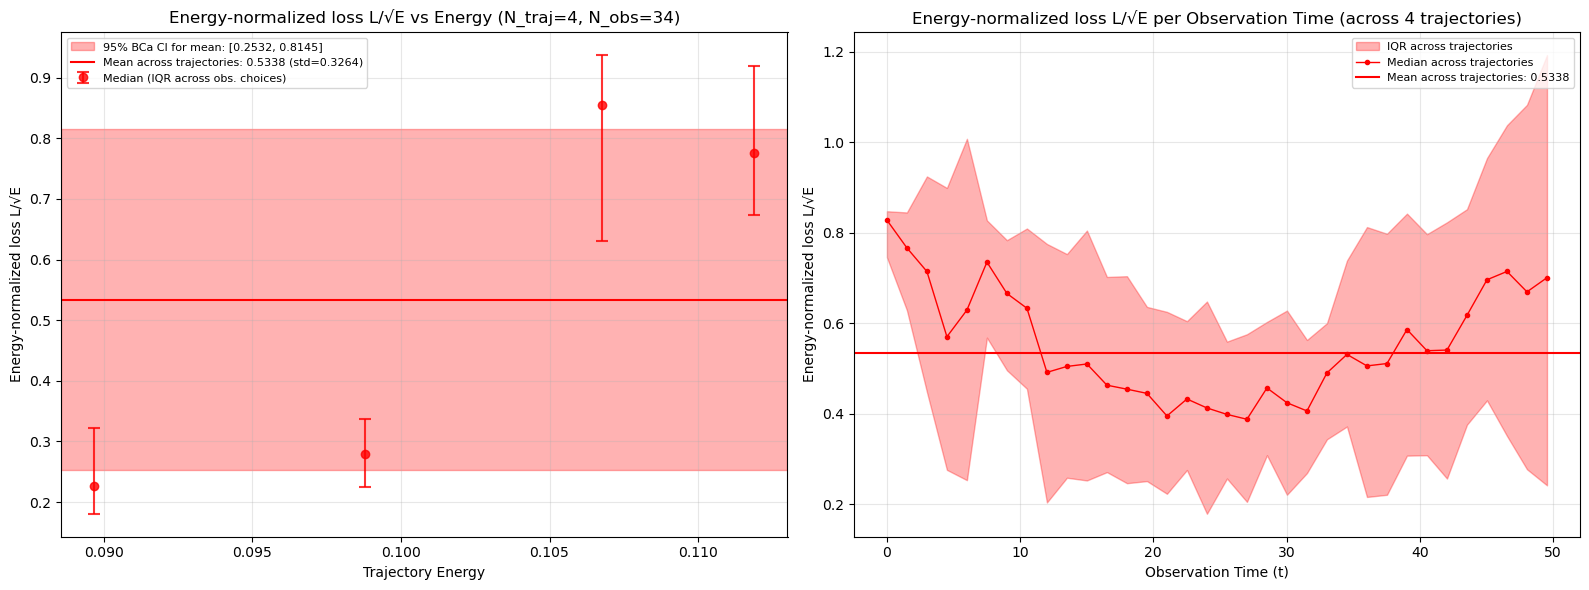

plot_summary_statistics: OK (no changes needed for general n)

L7  COST PROJECTION for the real run
reduced run: 32.9 s for 34 obs indices x 4 traj -> 0.968 s per obs index
full data  : 334 obs indices x 16 traj
projected  : ~5.4 min (batch is 4x wider, so treat as a LOWER bound)
  -> decide before launching; nothing here requires the full run.

DONE


In [48]:
# =====================================================================
#  GENERAL-n EVALUATION HARNESS : TEST SUITE  (single cell)
#  Nothing aborts on failure - every section prints and continues.
#  Runs on a REDUCED copy of the data (4 trajectories, strided time).
# =====================================================================


n        = 2
POS_COLS = ("x", "y")
MOM_COLS = ("px", "py")
Tmax     = 8.563
device   = next(mapping_net.parameters()).device
mapping_net.eval(); inverse_net.eval()

N_TRAJ_TEST = 4      # enough for cross-traj stacking, distinct energies, BCa
STRIDE      = 10     # keeps full [0,50] range -> Case 2 with ~6 windows/direction

def sec(s): print("\n" + "=" * 68 + f"\n{s}\n" + "=" * 68)

# ---------------- build reduced dataframes ----------------
SEL = [int(i) for i in test_id_df['trajectory_id'].values[:N_TRAJ_TEST]]
parts, meta, cursor = [], [], 0
for tid in SEL:
    tr = get_data_from_trajectory_id(test_id_df, test_df, [tid]).iloc[::STRIDE].reset_index(drop=True)
    row = test_id_df.loc[test_id_df['trajectory_id'] == tid].iloc[0]
    parts.append(tr)
    meta.append({'trajectory_id': tid, 'energy': float(row['energy']),
                 'generated_points': len(tr),
                 'start_index': cursor, 'end_index': cursor + len(tr)})
    cursor += len(tr)
small_df    = pd.concat(parts, ignore_index=True)
small_id_df = pd.DataFrame(meta)
t_small     = small_df['t'].to_numpy(np.float32)[:meta[0]['generated_points']]
print(f"reduced set: {N_TRAJ_TEST} trajectories x {len(t_small)} points, "
      f"t in [{t_small.min():.2f}, {t_small.max():.2f}], Tmax={Tmax}")
print(f"energies: {[m['energy'] for m in meta]}")


# =====================================================================
sec("L1  n=1 EXACTNESS: general loss on (N,1) vs current loss on (N,)")
# =====================================================================
try:
    g = torch.Generator().manual_seed(0)
    a, b, c, d = (torch.randn(200, generator=g).to(device) for _ in range(4))
    old = prediction_loss_euclidean(a, b, c, d)
    new = prediction_loss_euclidean_general(a.unsqueeze(1), b.unsqueeze(1),
                                            c.unsqueeze(1), d.unsqueeze(1), n=1)
    print(f"old = {old.item():.10f}")
    print(f"new = {new.item():.10f}")
    print(f"bitwise identical : {torch.equal(old, new)}   |diff| = {(old-new).abs().item():.3e}")
    print("  -> must be True: Task 1/2 published numbers are preserved exactly.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("L2  n=2 CORRECTNESS: general loss vs explicit hand computation")
# =====================================================================
try:
    xp = torch.tensor([[0.0, 0.0], [1.0, 2.0]], device=device)
    up = torch.tensor([[0.0, 0.0], [3.0, 4.0]], device=device)
    XL = torch.tensor([[3.0, 4.0], [1.0, 2.0]], device=device)
    UL = torch.tensor([[0.0, 0.0], [3.0, 0.0]], device=device)
    got = prediction_loss_euclidean_general(xp, up, XL, UL, n=2).item()
    # point 0: sqrt(9+16+0+0)=5 ; point 1: sqrt(0+0+0+16)=4 ; mean = 4.5
    print(f"got = {got:.10f}   expected = 4.5000000000   match = {abs(got-4.5) < 1e-6}")
    # explicit loop reference on random data
    xp = torch.randn(50, 2, device=device); up = torch.randn(50, 2, device=device)
    XL = torch.randn(50, 2, device=device); UL = torch.randn(50, 2, device=device)
    ref = np.mean([float(np.sqrt(((xp[k]-XL[k])**2).sum().item()
                                 + ((up[k]-UL[k])**2).sum().item())) for k in range(50)])
    got = prediction_loss_euclidean_general(xp, up, XL, UL, n=2).item()
    print(f"random data: got={got:.8f} loop-ref={ref:.8f} |diff|={abs(got-ref):.3e}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("L3  DECISIVE: spy-loss checks shapes and prediction assembly")
# =====================================================================
try:
    captured = []
    def spy_loss(x_pred, u_pred, X_labels, U_labels, n):
        captured.append((tuple(x_pred.shape), tuple(X_labels.shape),
                         x_pred.detach().cpu().numpy(), X_labels.detach().cpu().numpy()))
        return prediction_loss_euclidean_general(x_pred, u_pred, X_labels, U_labels, n)

    t0 = time.time()
    res_spy = test_model_all_observations_all_trajectories_general(
        get_data_from_trajectory_id, spy_loss, small_id_df, small_df,
        mapping_net, inverse_net, device, Tmax, n,
        pos_cols=POS_COLS, mom_cols=MOM_COLS, verbose=False)
    dt = time.time() - t0

    N_obs = res_spy['N_obs']; N_tr = res_spy['N_traj']
    shapes_ok = all(c[0] == (N_obs, n) and c[1] == (N_obs, n) for c in captured)
    print(f"loss called {len(captured)} times (expected {N_obs*N_tr}) : "
          f"{len(captured) == N_obs*N_tr}")
    print(f"all tensors shaped (N_obs, n) = ({N_obs}, {n}) : {shapes_ok}")

    # call k -> obs_idx = k // N_traj  (obs-major, traj-minor)
    bad = []
    for k, (_, _, xp_np, XL_np) in enumerate(captured):
        o = k // N_tr
        if not np.array_equal(xp_np[o], XL_np[o]):
            bad.append((k, o))
    print(f"row obs_idx of assembled prediction == ground truth, exactly: "
          f"{len(bad) == 0}  (violations: {len(bad)})")
    print("  -> proves x_pred_full assembly and the query index mapping are correct,")
    print("     independent of model quality.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("L4  shapes, dict keys, forward-pass counts vs paper formula")
# =====================================================================
try:
    print(f"loss_matrix {res_spy['loss_matrix'].shape} expected ({N_obs}, {N_tr}) : "
          f"{res_spy['loss_matrix'].shape == (N_obs, N_tr)}")
    expected_keys = {'loss_matrix','loss_matrix_normalized','loss_matrix_for_stats',
        'per_trajectory_median_loss','per_obs_mean_loss','summary_stats','trajectory_ids',
        'energies','t','N_obs','N_traj','confidence_level','normalized','forward_pass_stats',
        'all_mapping_net_calls','all_inverse_net_calls','median_representative_id',
        'median_representative_loss','n'}
    print(f"dict keys == n=1 keys + 'n' : {set(res_spy) == expected_keys}")
    if set(res_spy) != expected_keys:
        print(f"   diff: {set(res_spy) ^ expected_keys}")
    print(f"finite losses : {np.all(np.isfinite(res_spy['loss_matrix']))}")

    tt = res_spy['t']; tmn, tmx = float(tt[0]), float(tt[-1])
    mism = 0
    for o in range(N_obs):
        tob = float(tt[o])
        kf = max(int(np.ceil((tmx - tob)/Tmax - 1e-9)), 1) if np.any(tt > tob) else 0
        kb = max(int(np.ceil((tob - tmn)/Tmax - 1e-9)), 1) if np.any(tt < tob) else 0
        if res_spy['all_mapping_net_calls'][o] != kf + kb:
            mism += 1
    print(f"mapping-net calls == K_fwd+K_bwd for {N_obs-mism}/{N_obs} obs indices")
    print(f"   (mismatches are legitimate only if a window contained no query times)")
    print(f"calls per obs: mapping range "
          f"[{res_spy['forward_pass_stats']['mapping_net_min']}, "
          f"{res_spy['forward_pass_stats']['mapping_net_max']}]")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("L5  energy normalization is exactly loss / sqrt(E)")
# =====================================================================
try:
    lm = res_spy['loss_matrix']; ln = res_spy['loss_matrix_normalized']
    E  = res_spy['energies']
    manual = lm / np.sqrt(E)[np.newaxis, :]
    print(f"max |normalized - loss/sqrt(E)| = {np.abs(ln - manual).max():.3e}")
    print(f"loss_matrix_for_stats is the normalized one : "
          f"{np.array_equal(res_spy['loss_matrix_for_stats'], ln)}")
    pm = np.median(ln, axis=0)
    print(f"per_trajectory_median matches np.median(axis=0) : "
          f"{np.allclose(res_spy['per_trajectory_median_loss'], pm)}")
    ss = res_spy['summary_stats']
    print(f"CI brackets the mean : {ss['ci_lower'] <= ss['mean'] <= ss['ci_upper']}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("L6  plot_summary_statistics runs UNMODIFIED on general results")
# =====================================================================
try:
    plot_summary_statistics(res_spy, normalized=True)
    print("plot_summary_statistics: OK (no changes needed for general n)")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("L7  COST PROJECTION for the real run")
# =====================================================================
try:
    per_obs = dt / N_obs
    full_N_obs = int(test_id_df['generated_points'].iloc[0])
    full_N_traj = len(test_id_df)
    scale = full_N_traj / N_tr
    print(f"reduced run: {dt:.1f} s for {N_obs} obs indices x {N_tr} traj "
          f"-> {per_obs:.3f} s per obs index")
    print(f"full data  : {full_N_obs} obs indices x {full_N_traj} traj")
    print(f"projected  : ~{per_obs*full_N_obs/60:.1f} min "
          f"(batch is {scale:.0f}x wider, so treat as a LOWER bound)")
    print("  -> decide before launching; nothing here requires the full run.")
except Exception:
    traceback.print_exc()

print("\n" + "=" * 68 + "\nDONE\n" + "=" * 68)

reduced: trajectory 56, 34 points, t in [0.00, 49.55], Tmax=8.563
target energy from test_id_df: 0.1118987342

P1  n=1 EXACTNESS: prediction_loss_general vs prediction_loss
mse: old=4.4356036186  new=4.4356036186  bitwise=True
mae: old=2.3362207413  new=2.3362207413  bitwise=True
  -> both must be True: Task 1/2 published numbers preserved exactly.

P2  n=2: DOF axis is SUMMED (paper SE), not averaged
prediction_loss_general (mse) = 8.12430954
mean_t of paper SE(t)         = 8.12430954   match=True
n=1 function fed (T,n)        = 4.06215477   ratio good/naive = 2.0000 (should be n=2)

P3  ENERGY FUNCTION vs the data it was generated from
E(t) shape (334,)  mean=0.1118987342  target=0.1118987342
|mean(E) - target|      = 9.714e-17
max |E(t) - E(0)|       = 1.249e-16
relative drift          = 1.116e-15
  -> must recover the sampler's target energy and be conserved along
     the trajectory; this validates the Hamiltonian against your data.

P4  single-trajectory general: 7-tuple shapes, 

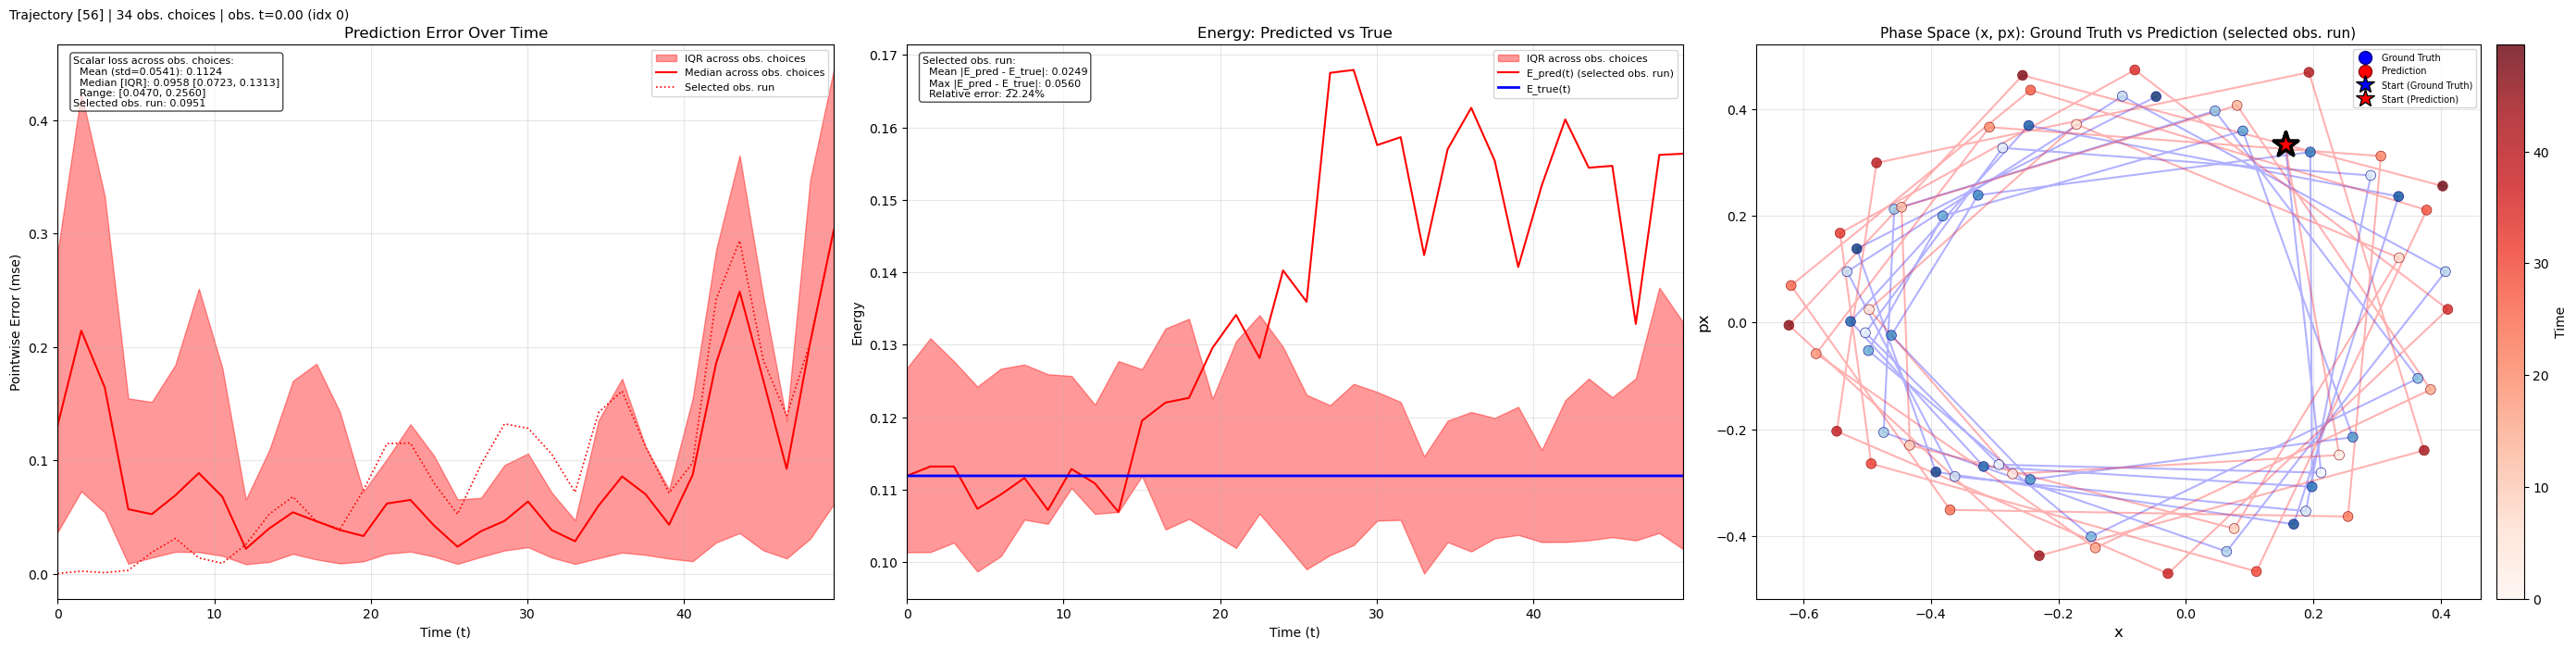

  phase_coords=None: OK


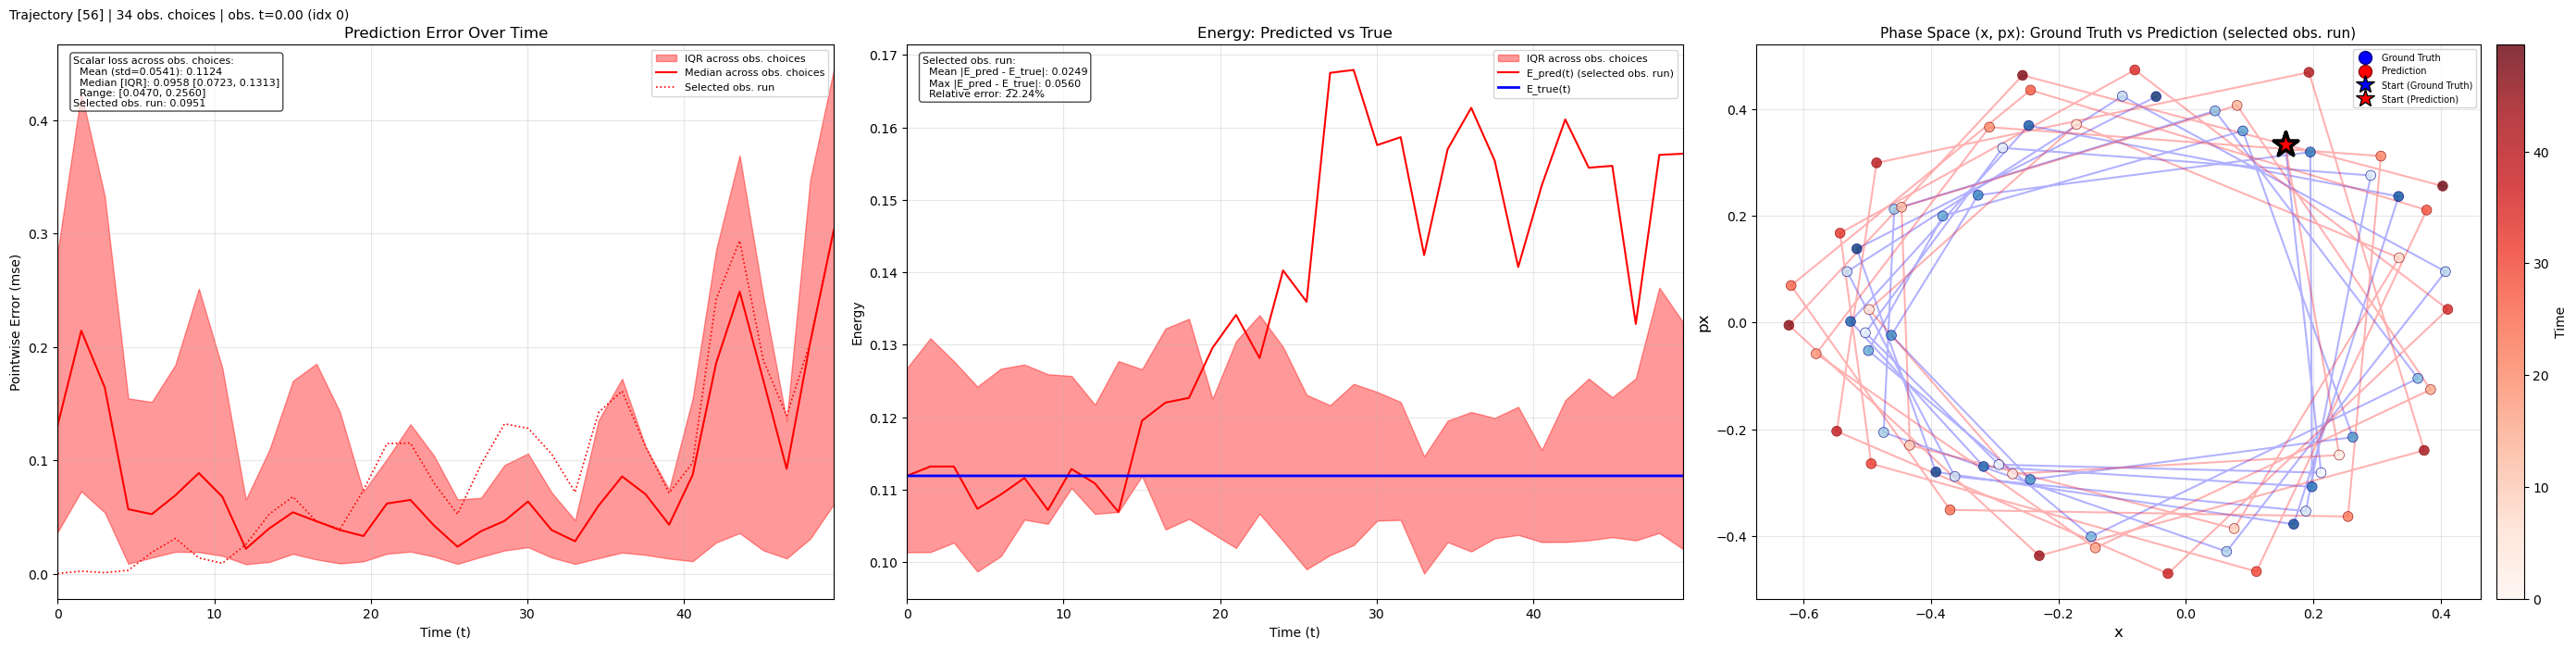

  phase_coords=('x', 'px'): OK


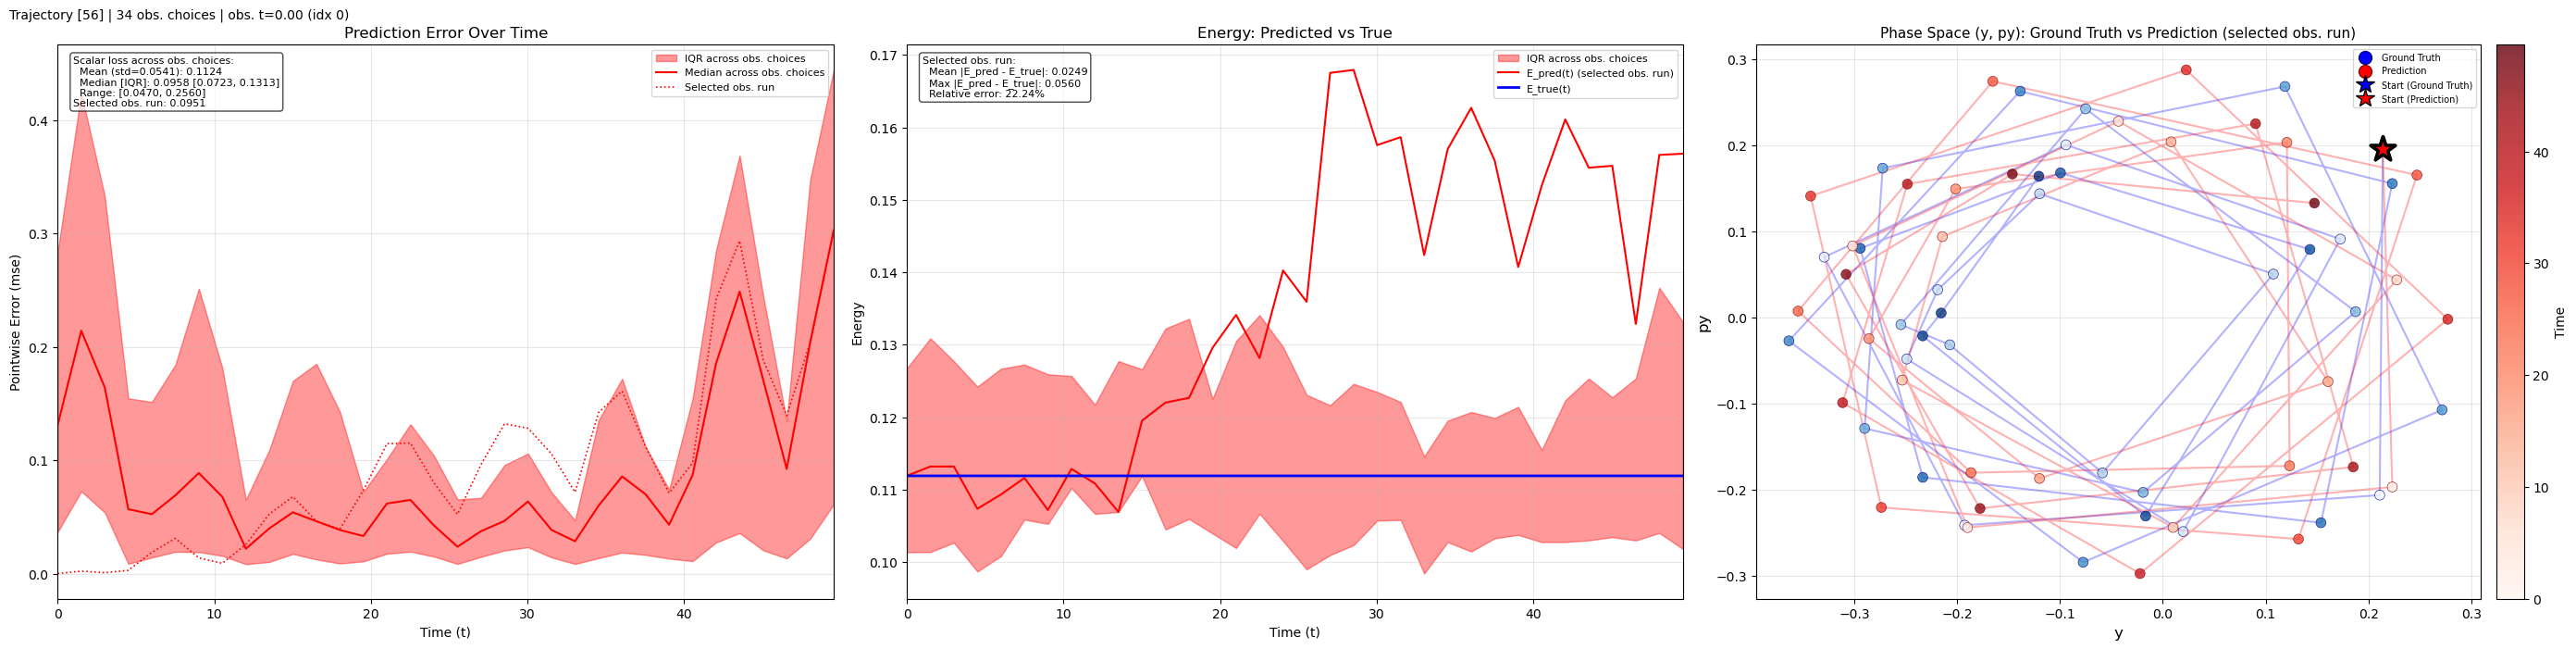

  phase_coords=('y', 'py'): OK


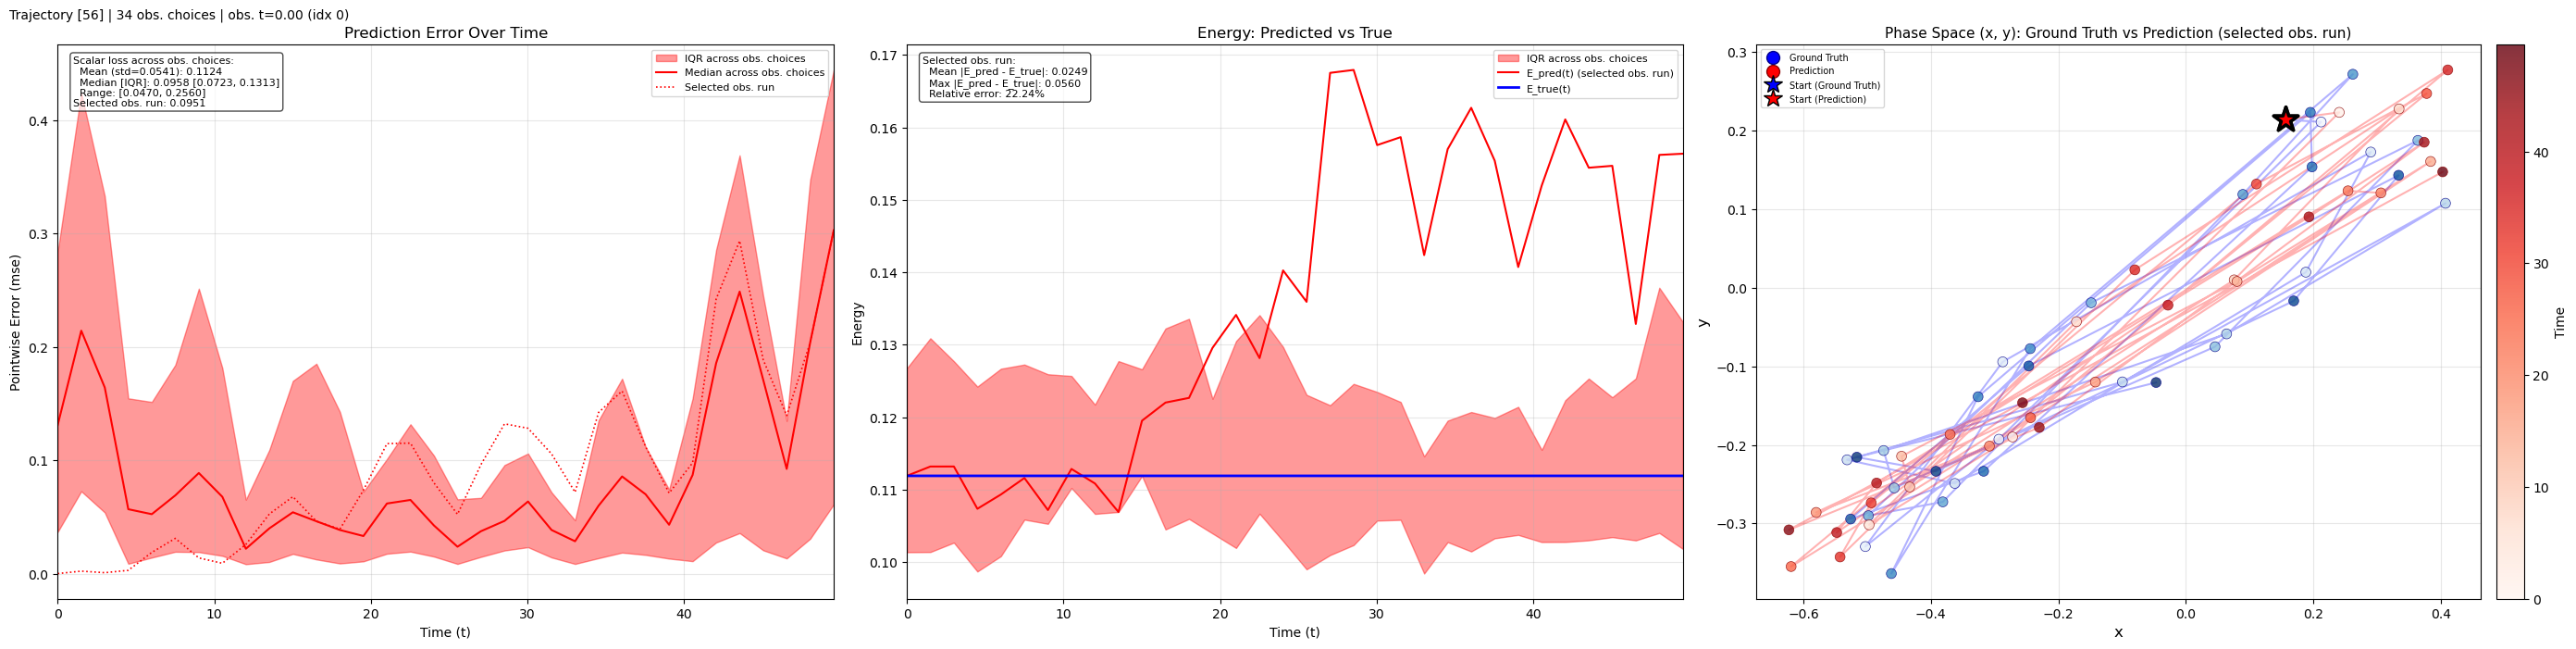

  phase_coords=('x', 'y'): OK
  rejected ('x', 'x'): phase_coords must name two distinct coordinates, got ('x', '
  rejected ('x', 'q'): unknown coordinate 'q'; available: ['x', 'y', 'px', 'py']
  rejected ('x', 'px', 'y'): phase_coords must name exactly two coordinates, got ('x', 'p

P7  COST PROJECTION for the real run
reduced: 31.5 s for 34 obs choices -> 0.927 s per run
full   : 334 obs choices -> ~5.2 min per trajectory
  -> unbatched by design (N sequential single-trajectory inferences).

DONE


In [54]:
# =====================================================================
#  GENERAL-n VARYING-OBSERVATION DIAGNOSTIC : TEST SUITE  (single cell)
#  Nothing aborts on failure - every section prints and continues.
#  Runs on a REDUCED copy of one trajectory (strided time).
# =====================================================================


n        = 2
POS_COLS = ("x", "y")
MOM_COLS = ("px", "py")
Tmax     = 8.563
LOSS     = "mse"                 # the loss_type used for the paper's L_m
device   = next(mapping_net.parameters()).device
mapping_net.eval(); inverse_net.eval()

STRIDE = 10                      # keeps full [0,50] range -> Case 2 autoregression

def sec(s): print("\n" + "=" * 68 + f"\n{s}\n" + "=" * 68)

energy_hh = make_energy_henon_heiles(lam=1.0)

# ---------------- reduced single-trajectory frames ----------------
tid = int(test_id_df['trajectory_id'].iloc[0])
tr  = get_data_from_trajectory_id(test_id_df, test_df, [tid]).iloc[::STRIDE].reset_index(drop=True)
row = test_id_df.loc[test_id_df['trajectory_id'] == tid].iloc[0]
small_df    = tr.copy()
small_id_df = pd.DataFrame([{'trajectory_id': tid, 'energy': float(row['energy']),
                             'generated_points': len(tr),
                             'start_index': 0, 'end_index': len(tr)}])
print(f"reduced: trajectory {tid}, {len(tr)} points, "
      f"t in [{tr['t'].min():.2f}, {tr['t'].max():.2f}], Tmax={Tmax}")
print(f"target energy from test_id_df: {float(row['energy']):.10f}")


# =====================================================================
sec("P1  n=1 EXACTNESS: prediction_loss_general vs prediction_loss")
# =====================================================================
try:
    g = torch.Generator().manual_seed(0)
    a, b, c, d = (torch.randn(200, generator=g).to(device) for _ in range(4))
    for lt in ("mse", "mae"):
        old = prediction_loss(a, b, c, d, loss_type=lt)
        new = prediction_loss_general(a.unsqueeze(1), b.unsqueeze(1),
                                      c.unsqueeze(1), d.unsqueeze(1), n=1, loss_type=lt)
        print(f"{lt}: old={old.item():.10f}  new={new.item():.10f}  "
              f"bitwise={torch.equal(old, new)}")
    print("  -> both must be True: Task 1/2 published numbers preserved exactly.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("P2  n=2: DOF axis is SUMMED (paper SE), not averaged")
# =====================================================================
try:
    g = torch.Generator().manual_seed(1)
    A, B, C, D = (torch.randn(60, 2, generator=g).to(device) for _ in range(4))
    naive = prediction_loss(A, B, C, D, loss_type="mse")           # WRONG: averages DOF
    good  = prediction_loss_general(A, B, C, D, n=2, loss_type="mse")
    se    = ((A - C)**2).sum(-1) + ((B - D)**2).sum(-1)            # paper SE(t)
    print(f"prediction_loss_general (mse) = {good.item():.8f}")
    print(f"mean_t of paper SE(t)         = {se.mean().item():.8f}   "
          f"match={abs(good.item()-se.mean().item()) < 1e-5}")
    print(f"n=1 function fed (T,n)        = {naive.item():.8f}   "
          f"ratio good/naive = {(good/naive).item():.4f} (should be n={n})")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("P3  ENERGY FUNCTION vs the data it was generated from")
# =====================================================================
try:
    full = get_data_from_trajectory_id(test_id_df, test_df, [tid])
    q_gt = full[list(POS_COLS)].to_numpy(np.float64)
    p_gt = full[list(MOM_COLS)].to_numpy(np.float64)
    E = energy_hh(q_gt, p_gt)
    E_target = float(row['energy'])
    print(f"E(t) shape {E.shape}  mean={E.mean():.10f}  target={E_target:.10f}")
    print(f"|mean(E) - target|      = {abs(E.mean()-E_target):.3e}")
    print(f"max |E(t) - E(0)|       = {np.abs(E - E[0]).max():.3e}")
    print(f"relative drift          = {np.abs(E-E[0]).max()/abs(E[0]):.3e}")
    print("  -> must recover the sampler's target energy and be conserved along")
    print("     the trajectory; this validates the Hamiltonian against your data.")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("P4  single-trajectory general: 7-tuple shapes, obs point exact")
# =====================================================================
try:
    T_small = len(tr)
    ob = T_small // 2
    out = test_model_in_single_trajectory_general(
        get_data_from_trajectory_id, LOSS, small_id_df, small_df, [tid],
        mapping_net, inverse_net, device, [ob], Tmax, n,
        pos_cols=POS_COLS, mom_cols=MOM_COLS, verbose=False)
    pl, xp, up, xg, ug, tg, fc = out
    print(f"tuple length {len(out)} (expected 7)")
    print(f"x_pred {tuple(xp.shape)}  u_pred {tuple(up.shape)}  "
          f"x {tuple(xg.shape)}  t {tuple(tg.shape)}   expected ({T_small}, {n}) / ({T_small},)")
    same = torch.equal(xp[ob], xg[ob]) and torch.equal(up[ob], ug[ob])
    print(f"observation row is ground truth exactly : {same}")
    print(f"loss scalar = {pl.item():.8f}   fwd_count = {fc}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("P5  varying-observation general: shapes, stats, paper consistency")
# =====================================================================
try:
    t0 = time.time()
    res = test_model_varying_observation_single_trajectory_general(
        get_data_from_trajectory_id, LOSS, small_id_df, small_df, [tid],
        mapping_net, inverse_net, device, Tmax, n,
        pos_cols=POS_COLS, mom_cols=MOM_COLS,
        energy_function=energy_hh, verbose=False)
    dt = time.time() - t0
    N, T = res['N'], res['T']
    print(f"N={N} T={T} n={res['n']}  case={res['case']}")
    checks = {
        "x (T,n)":            res['x'].shape == (T, n),
        "all_x_pred (N,T,n)": res['all_x_pred'].shape == (N, T, n),
        "all_u_pred (N,T,n)": res['all_u_pred'].shape == (N, T, n),
        "pointwise (N,T)":    res['pointwise_errors'].shape == (N, T),
        "energy_true (T,)":   res['energy_true'].shape == (T,),
        "all_energy (N,T)":   res['all_energy_pred'].shape == (N, T),
        "per_run (N,)":       res['per_run_losses'].shape == (N,),
    }
    for k, v in checks.items():
        print(f"  {k:22s}: {v}")

    # paper: L_m = mean over prediction times of SE(t)
    ref = res['pointwise_errors'].mean(axis=1)
    dev = np.abs(res['per_run_losses'] - ref).max()
    rel = dev / max(np.abs(ref).max(), 1e-30)
    print(f"max |L_m - mean_t SE^(m)(t)| = {dev:.3e}   relative = {rel:.3e}")
    print(f"   (paper's definition; loss is float32 torch, SE is float64 numpy,")
    print(f"    so expect relative ~1e-7, NOT exact zero)")

    # per-timepoint stats must exclude the self-observation run
    j = T // 2
    m = np.ones(N, bool); m[j] = False
    print(f"per-timepoint median excludes self-obs : "
          f"{np.isclose(res['per_timepoint_stats']['median'][j], np.median(res['pointwise_errors'][m, j]))}")
    print(f"self-obs pointwise error at its own time = "
          f"{res['pointwise_errors'][j, j]:.3e} (should be ~0)")

    ss = res['summary_stats']
    print(f"summary: median={ss['median']:.6f} IQR=[{ss['q1']:.6f}, {ss['q3']:.6f}] "
          f"range=[{ss['min']:.6f}, {ss['max']:.6f}]")
    rel_E = (np.abs(res['all_energy_pred'][res['representative_idx']] - res['energy_true']).mean()
             / np.abs(res['energy_true']).mean())
    print(f"relative energy error (representative run) = {rel_E*100:.3f}%")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("P6  plot: phase_coords selection, never more than 3 panels")
# =====================================================================
try:
    for pc in [None, ('x', 'px'), ('y', 'py'), ('x', 'y')]:
        plot_varying_observation_results_general(res, obs_idx=0, phase_coords=pc)
        print(f"  phase_coords={pc}: OK")
    for bad in [('x', 'x'), ('x', 'q'), ('x', 'px', 'y')]:
        try:
            plot_varying_observation_results_general(res, obs_idx=0, phase_coords=bad)
            print(f"  FAIL: {bad} did not raise")
        except ValueError as e:
            print(f"  rejected {bad}: {str(e)[:60]}")
except Exception:
    traceback.print_exc()


# =====================================================================
sec("P7  COST PROJECTION for the real run")
# =====================================================================
try:
    per_run = dt / res['N']
    full_T = int(test_id_df['generated_points'].iloc[0])
    print(f"reduced: {dt:.1f} s for {res['N']} obs choices -> {per_run:.3f} s per run")
    print(f"full   : {full_T} obs choices -> ~{per_run*full_T/60:.1f} min per trajectory")
    print("  -> unbatched by design (N sequential single-trajectory inferences).")
except Exception:
    traceback.print_exc()

print("\n" + "=" * 68 + "\nDONE\n" + "=" * 68)